<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_VerifiedRobustness_Guan2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Verifying adversarial robustness of quantum classifiers (fidelity bounds, SDP, Mask-FGSM, VeriQR): Guan and Ying (2026) step by step

**Paper.** Ji Guan and Mingsheng Ying, *Verifying Adversarial Robustness in Quantum Machine Learning: from theory to physical validation via a software toolchain*, book chapter (Springer, 2026), arXiv:2605.29877 [quant-ph], DOI [10.1007/978-3-032-11153-1_10](https://doi.org/10.1007/978-3-032-11153-1_10). The chapter is a review of the authors' framework: a certified **fidelity-based robustness lower bound** computed from the measurement distribution (Theorem 2), the **optimal radius via semidefinite programming** (Theorem 1), an empirical **upper bound from adversarial attacks** (Mask-FGSM, Theorem 3), the verification **Algorithms 1 to 3**, the tool **VeriQR**, and a **20-qubit superconducting-processor benchmark** (EMNIST letters "Q" vs "T" and linear-cluster-state excitation identification, LCEI).

**What this notebook does.** Everything in the chapter that can be re-run on a classical CPU is re-run, from scratch and with our own code:

1. the bounds `eps_RLB <= eps* <= eps_RUB` are implemented and tested on random noisy quantum classifiers, where the exact radius `eps*` is obtained from the SDP of Theorem 1 (solved through its scalar Lagrange dual and cross-checked with a primal QCQP solver);
2. a **simulated version of the hardware benchmark**: a hardware-efficient QNN (SU(2) gates plus CZ chain) is trained on 600 real EMNIST images of "Q" and "T" and on the synthetic LCEI cluster-state dataset; Mask-FGSM gives `eps_RUB`, the closed form gives `eps_RLB`, the gap is measured on 10 random states (5 per class) as in the paper, and clean training is compared with adversarial training (mean lower bound of the 20% most fragile "critical" samples);
3. **Algorithms 2 and 3 of the VeriQR toolchain** (exact verification vs. the cheap under-approximation) on the authors' own public example model `mnist01` (8-qubit OpenQASM circuit plus 1000 amplitude-encoded MNIST states), with and without noise.

**What cannot be re-run.** The 20-qubit superconducting processor, its quantum state tomography and the hardware noise are not available; the chapter's hardware numbers are therefore compared with *noiseless simulations with a smaller circuit* and are flagged as such in the final table. Real-hardware cells would run only if `IBM_TOKEN` is set; none is needed here.

**How to run.** Open in Google Colab (CPU runtime is enough) and choose *Runtime -> Run all*. The committed run used `FAST_MODE = False` (the longer training budgets of the configuration cell; about 27 minutes on a shared 8-core CPU, an 8-qubit exact simulator); `FAST_MODE = True` shortens training and finishes in roughly 15 minutes with lower EMNIST accuracy. All datasets are public and downloaded inside the notebook (EMNIST letters from the Hugging Face mirror `tanganke/emnist_letters`, the VeriQR example files from the authors' GitHub at a pinned commit). No token is needed; for a *gated* dataset you would store your own `HF_TOKEN` in Colab Secrets (this notebook reads it only from `os.environ` or Colab Secrets and never prints or stores it).

**What you get at the end.** Per-sample certified lower bounds and attack-based upper bounds for the simulated benchmark, the effect of adversarial training on the certificates, Algorithm 2 vs Algorithm 3 robust accuracies and timings for the VeriQR model, the chapter's Figures 1.2 and 1.6 re-drawn from our own numbers, and a table that states for every checkable claim whether it is reproduced.

## The paper in one page

**Setting.** A quantum classifier is `A = (E, {M_c})`: a quantum channel `E` (CPTP, noise included) followed by a POVM `{M_c}`; the label is `A(rho) = argmax_c Tr[M_c E(rho)]`. States are compared with the **fidelity** `F(rho, sigma) = (Tr sqrt(sqrt(rho) sigma sqrt(rho)))^2` and the **fidelity distance** `D_F = 1 - F`. A state `sigma` with `D_F(rho, sigma) <= eps` and a different label is an *eps-adversarial example*; the **robustness radius** `eps*(rho)` is the smallest such distance; the **robust accuracy** is the fraction of correctly classified states that are eps-robust.

**Three bounds on the radius.**

* *Optimal (Theorem 1).* `eps*_c(rho) = min D_F(rho, sigma)` s.t. `sigma >= 0, Tr sigma = 1, Tr[(M_A(rho) - M_c) E(sigma)] <= 0` is a **semidefinite program** (SDP); `eps* = min_{c != A(rho)} eps*_c`. Cost `O(|C| N^6.5)` for dimension `N`. For pure adversarial states it becomes a QCQP (NP-hard in general).
* *Lower bound (Theorem 2).* From the measured distribution `p_c = Tr[M_c E(rho)]` alone: `eps_RLB(rho) = min_{c != c*} (1/2) (sqrt(p_c*) - sqrt(p_c))^2`; no state or circuit access is needed, so it can be estimated on hardware from repeated shots.
* *Upper bound (Definition 7).* Any attack that finds `sigma_adv` with another label gives `eps_RUB = D_F(rho, sigma_adv)`. Theorem 3: `eps_RLB <= eps* <= eps_RUB`. The attack used on hardware is **Mask-FGSM**: FGSM restricted to the top-`r` fraction of input coordinates ranked by the mean absolute gradient (`r ~ 0.15` for EMNIST, `delta_i = eps sgn(dL/dx_i)` for `i` in the mask).

**Algorithms.** Alg. 1 (state verifier, SDP per wrong class), Alg. 2 (dataset verifier: use the lower bound as a filter and call Alg. 1 only for states with `eps > eps_RLB`; exact robust accuracy), Alg. 3 (only the filter; an **under-approximation** of the robust accuracy, matrix-multiplication cost). Table 1.1: complexity `O(|T||C|N^5)` vs `O(|T||C|N^6.5)` vs `O(|T'||C|N^6.5)`, `|T'| << |T|`.

**Hardware benchmark (Section 1.6, source experiment Zhang et al.).** 20-qubit superconducting processor. Classical task: EMNIST "Q" vs "T" (600 images, 500 train / 100 test, resized to 15 x 15). Quantum task: LCEI, `|LC_n> = prod CZ_{i,i+1} |+>^n` followed by `R_x(alpha)`, "excited" if `|alpha| > pi/2`; 150 angles sampled from `[0, 3pi/8]` and `[5pi/8, pi]`, 200 train / 100 test. Binary classification from `<sigma_z>` of the output qubit, `p = (<sigma_z> + 1)/2`, threshold 0.5. Benchmark on **10 random states (5 per class)**: measure `p`, compute `eps_RLB`, attack with Mask-FGSM to get `eps_RUB`, retrain adversarially, compare.

**Claims that can be checked.** (1) `eps_RLB <= eps* <= eps_RUB` always. (2) The average gap `eps_RUB - eps_RLB` is `2.96e-3` (EMNIST) and `3.25e-3` (LCEI), "typically below 3e-3" (hardware). (3) Adversarial training raises the mean certified lower bound of the 20% most fragile ("critical") samples by a factor `4.22` (EMNIST) and `4.74` (LCEI) (hardware). (4) Algorithm 3 is much faster than Algorithm 2 and under-approximates its robust accuracy. (5) Source-experiment accuracies (clean training): 96% test (EMNIST), 100% (LCEI); after adversarial training 88% legitimate / 87% adversarial (EMNIST), 100% / 100% (LCEI).

## What follows the paper and what had to be chosen

The chapter is a review: the circuit details of the hardware QNNs live in the supplementary material of the source experiment, which is not part of the chapter. Everything that is not stated is chosen below and marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Number of qubits | 20-qubit superconducting processor | **8 qubits** simulated exactly (a 20-qubit, 40-layer circuit is too slow to train on a shared CPU); the output qubit is qubit 0 |
| Circuit | hardware-efficient: SU(2) gate on every qubit, nearest-neighbour CZ, 40 layers, 181 trainable parameters | same family: `Rot(phi, theta, omega)` on every qubit + CZ chain; **10 layers** (EMNIST) and **6 layers** (LCEI) at 8 qubits |
| EMNIST encoding | "interleaved block encoding": features enter the SU(2) gate angles through linear combinations | gate angle `= w_g + s_g * x_(g mod 225)`: each of the 240 gate angles carries one pixel of the 15 x 15 image (scaled to `[0, pi]`) with trainable offset `w_g` and scale `s_g` (`# CHOICE:`) |
| LCEI encoding | cluster state + `R_x(alpha)` then the variational circuit | identical: `H`, CZ chain, `R_x(alpha_i)` on qubit `i` (all `alpha_i = alpha` for a data point), then the variational circuit; the attack perturbs the per-qubit angles `alpha_i` under a mask |
| Data | EMNIST "Q"/"T": 600 images, 500/100; LCEI: 150 angles per class, 200/100 | same sizes; EMNIST from the HF mirror `tanganke/emnist_letters` (test split, 800 images per letter, 300 per class drawn with `SEED`) |
| Training | Adam, mini-batches, epochs not given | Adam, lr 0.05, batch 50, binary cross-entropy on `p` (`# CHOICE:`) |
| Output state / fidelity | `D(rho, sigma)` measured by quantum state tomography of the reduced density matrix of the output qubit | the exact reduced density matrix of the output qubit from the simulator; qubit fidelity `F = Tr(rho sigma) + 2 sqrt(det rho det sigma)` |
| Mask-FGSM | top-`r` mask (`r ~ 0.15`, >= 90% of the L1 gradient norm), cos^2 fits of `p(eps)` and `D(eps)` on hardware | same mask rule (`r = 0.15`; for LCEI the smallest qubit set covering >= 90% of the L1 norm); iterative sign steps of 0.5% of the data range, then bisection to the exact decision boundary `p = 0.5` (no fitting needed in an exact simulator) |
| Adversarial training | 200 adversarial samples (100 per class), mini-batches 50% legitimate / 50% adversarial | same; the adversarial samples are the boundary point pushed 20% further (`ADV_OVERSHOOT`, `# CHOICE:`), starting from the clean weights |
| Benchmark protocol | 10 random states (5 per class); critical = 20% lowest robustness | same 10 states, and additionally all 100 test states (so that the critical set has 20 elements instead of 2) |
| Exact radius (Theorem 1) | SDP | the SDP for a pure input has one linear constraint; it is solved through its **scalar Lagrange dual** (strong duality, Slater) and cross-checked against a primal QCQP solver (no `cvxpy` needed) |
| VeriQR | C++/Qt tool, SDP/QCQP solvers | Python re-implementation of Algorithms 2 and 3 on the tool's own `mnist01` example (pinned commit); qubit ordering of the QASM file vs the data file is not documented, we use the one that classifies best (documented below) |
| Hardware | 20-qubit chip, tomography, real noise | **cannot be re-run**; flagged "cannot be checked" |

In [1]:
# Install (Colab or a fresh local environment). Pinned to the versions this notebook was tested with.
# Colab already ships numpy, pandas, scikit-learn, matplotlib, torch, pillow, pyarrow, requests.
# If pip reports that a package was upgraded, restart the runtime once and run all cells again.
import sys, importlib, subprocess
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("pennylane", "qiskit", "torch", "pyarrow", "PIL", "huggingface_hub", "pylatexenc"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "qiskit==2.5.2",
                    "pylatexenc", "huggingface_hub", "pyarrow"], check=True)
    print("packages installed")
else:
    print("all required packages are already available")

all required packages are already available


In [2]:
# Configuration: every tunable constant lives here.
import time
T0 = time.time()                       # wall-clock start of the run
SEED = 42                              # global seed
FAST_MODE = False                       # True: a few minutes; False: longer training budgets (see below)
DATA_DIR = "qc126_data"                # downloads are cached here
IBM_TOKEN = ""                         # optional; real hardware is NOT used by this notebook

# --- quantum classifier (CHOICE: 8 qubits instead of the paper's 20, see the "what had to be chosen" table)
N_QUBITS = 8
L_EMNIST = 10                          # variational layers, EMNIST model (80 gate angles per 8 qubits x 3)
L_LCEI = 6                             # variational layers, LCEI model
IMG = 15                               # EMNIST images resized to IMG x IMG (paper: 15 x 15)

# --- data sizes as in the paper
N_PER_CLASS = 300                      # EMNIST: 300 "Q" + 300 "T"
N_TRAIN, N_TEST = 500, 100
LCEI_PER_CLASS, LCEI_TRAIN = 150, 200  # 300 states, 200 train / 100 test
EMNIST_LABELS = {"Q": 16, "T": 19}     # zero-based letter indices of the HF mirror (A = 0)

# --- training budgets (paper: epochs not stated).  Full budgets are used when FAST_MODE = False.
BATCH, LR = 50, 0.05
EPOCHS_CLEAN = {"emnist": 6 if FAST_MODE else 60, "lcei": 25 if FAST_MODE else 100}
EPOCHS_ADV = {"emnist": 4 if FAST_MODE else 30, "lcei": 10 if FAST_MODE else 40}
LR_ADV = 0.02

# --- attack and certificate settings
STEP = 0.005                           # Mask-FGSM step, fraction of the data range (x_max - x_min = pi)
MAX_ITERS = 400                        # iterations before an attack is declared failed (2 x the data range)
MASK_R = 0.15                          # EMNIST mask: top 15% of pixels (paper)
ADV_OVERSHOOT = 1.2                    # adversarial training samples sit 20% beyond the decision boundary
N_ADV_TRAIN = 100 if FAST_MODE else 200  # adversarial samples used in adversarial training (paper: 200)
N_PROTOCOL = 10                        # the paper's benchmark uses 10 states (5 per class)
SHOTS = 4096                           # shots used for the finite-shot lower bound estimate

# --- theory checks and VeriQR toolchain
N_RANDOM_CLASSIFIERS = 12 if FAST_MODE else 40
VERIQR_COMMIT = "ee326c0fa041971a496a35bea17ec5f4e649cb38"   # pinned commit of github.com/Veri-Q/VeriQR
N_VERIQR = 300 if FAST_MODE else 1000     # states of the VeriQR mnist01 file that are verified
print(f"FAST_MODE={FAST_MODE}  qubits={N_QUBITS}  epochs clean={EPOCHS_CLEAN}  adv={EPOCHS_ADV}")

FAST_MODE=False  qubits=8  epochs clean={'emnist': 60, 'lcei': 100}  adv={'emnist': 30, 'lcei': 40}


In [3]:
import os, sys, io, math, json, random, gzip, struct, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import pennylane as qml
import scipy
from scipy.optimize import minimize, minimize_scalar, NonlinearConstraint
import sklearn
from sklearn.decomposition import PCA
import requests
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
from PIL import Image

warnings.filterwarnings("ignore", category=UserWarning)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
DATA = Path(DATA_DIR); DATA.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})

# Hugging Face token: only from the environment or Colab Secrets, never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__, "| pandas", pd.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| sklearn", sklearn.__version__)

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6
torch 2.14.1+cpu | pennylane 0.45.1 | qiskit 2.5.2 | sklearn 1.9.1


## Part 1. The bounds and the algorithms, written from the paper

### Fidelity and Theorem 2 (the lower bound from the measurement distribution)

For a binary classifier with `p1 = max(p, 1 - p)` and `p2 = 1 - p1` the bound is `eps_RLB = (1/2)(sqrt(p1) - sqrt(p2))^2`. For more classes the paper's formula is the minimum over the wrong classes `c` of `(1/2)(sqrt(p_c*) - sqrt(p_c))^2`. It follows from the monotonicity of fidelity under the channel plus a Bhattacharyya-coefficient argument, so it holds for **every** channel including noise. `fidelity_qubit` is the closed form for two single-qubit states (needed for the output-qubit tomography of the hardware experiment).

### Theorem 1 (the exact radius as an SDP) solved without an SDP package

For a *pure* input `rho = |psi><psi|` the objective `1 - F = 1 - <psi|sigma|psi>` is linear and the constraint `Tr[(M_a - M_c) E(sigma)] <= 0` is one linear inequality `Tr[C sigma] <= 0` with `C = E*(M_a - M_c)` (Heisenberg picture). Its Lagrange dual is the scalar convex problem
`max_sigma <psi|sigma|psi>  =  min_{mu >= 0} lambda_max(|psi><psi| - mu C)`
(strong duality holds, Slater). The largest eigenvalue of a rank-one perturbation is the largest root of the secular equation `sum_i |<i|psi>|^2 / (lambda + mu c_i) = 1` (`c_i` are the eigenvalues of `C`), solved by bisection; the outer minimisation over `mu` uses a bounded Brent search over `mu = tan(t)`. So `eps* = 1 - min_mu lambda_max(...)`. A primal QCQP solver is used below to confirm numerically that the dual is attained.

In [4]:
# ---------------------------------------------------------------------------------------------
# Theory toolbox.  p-vectors are class probabilities; C is the Heisenberg-picture constraint operator.
# ---------------------------------------------------------------------------------------------
def fidelity_qubit(rho, sigma):
    """F(rho, sigma) = (Tr sqrt(sqrt(rho) sigma sqrt(rho)))^2 for 2x2 states (batched, torch or numpy)."""
    rho = torch.as_tensor(rho); sigma = torch.as_tensor(sigma)
    tr = (rho * sigma.transpose(-1, -2)).sum((-1, -2)).real          # Tr(rho sigma)
    det = (torch.linalg.det(rho) * torch.linalg.det(sigma)).real.clamp_min(0.0)
    return (tr + 2.0 * torch.sqrt(det)).clamp(0.0, 1.0)

def rlb_binary(p1):
    """Theorem 2 for two classes: eps_RLB = 0.5 (sqrt(p1) - sqrt(p2))^2 with p1 = max(p, 1-p)."""
    p1 = np.asarray(p1, float); big = np.maximum(p1, 1 - p1); small = 1 - big
    return 0.5 * (np.sqrt(big) - np.sqrt(small)) ** 2

def rlb_multiclass(p):
    """Theorem 2: min over the wrong classes c of 0.5 (sqrt(p_c*) - sqrt(p_c))^2."""
    p = np.asarray(p, float); cstar = int(np.argmax(p))
    return float(min(0.5 * (np.sqrt(p[cstar]) - np.sqrt(p[c])) ** 2 for c in range(len(p)) if c != cstar))

def _lam_max_rank1(c, w, mu):
    """Largest eigenvalue of |psi><psi| - mu C, via the secular equation sum w_i / (lam + mu c_i) = 1."""
    a = mu * c
    lo = float((-a).max()); hi = lo + 1.0              # F(lam) = sum w/(lam+a) - 1 decreases from +inf to <= 0
    for _ in range(90):
        mid = 0.5 * (lo + hi)
        if np.sum(w / (mid + a)) > 1.0:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)

class ExactVerifier:
    """Exact robustness radius (Theorem 1) of a pure input state for ONE linear constraint Tr[C sigma] <= 0."""
    def __init__(self, C):
        C = 0.5 * (C + C.conj().T)
        self.c, self.V = np.linalg.eigh(C)
    def radius(self, psi):
        amp = self.V.conj().T @ psi
        w = np.abs(amp) ** 2; w = w / w.sum()
        m = w > 1e-14                                    # eigen-directions with no weight do not matter
        c, w = self.c[m], w[m]
        if float(np.sum(w * c)) <= 0.0:
            return 0.0                                   # already violates the constraint (not robust at any eps)
        if self.c.min() > 0:
            return float("inf")                          # constraint can never be met: no adversarial state
        cmin_all = float(self.c.min())
        f = lambda t: max(_lam_max_rank1(c, w, math.tan(t)), -math.tan(t) * cmin_all)   # also the weightless directions
        res = minimize_scalar(f, bounds=(1e-9, math.pi / 2 - 1e-9), method="bounded", options=dict(xatol=1e-13, maxiter=200))
        return float(max(0.0, 1.0 - min(res.fun, 1.0)))

def primal_pure_radius(psi, C, rng, starts=6):
    """Primal check: pure-state QCQP  min 1 - |<psi|phi>|^2  s.t. <phi|C|phi> <= 0  (SLSQP from several starts)."""
    d = len(psi); best = np.inf
    ev, V = np.linalg.eigh(0.5 * (C + C.conj().T))
    neg = V[:, 0]                                         # eigenvector of the most negative eigenvalue (feasible)
    def to_c(x): return x[:d] + 1j * x[d:]
    obj = lambda x: 1.0 - abs(np.vdot(psi, to_c(x))) ** 2 / np.vdot(to_c(x), to_c(x)).real
    con = lambda x: -(np.vdot(to_c(x), C @ to_c(x)).real / np.vdot(to_c(x), to_c(x)).real)
    starts_x = []
    for s in range(starts):
        t = rng.uniform(0.2, 0.8); v = (1 - t) * psi + t * neg + 0.05 * (rng.normal(size=d) + 1j * rng.normal(size=d))
        starts_x.append(np.concatenate([v.real, v.imag]))
    for x0 in starts_x:
        r = minimize(obj, x0, method="SLSQP", constraints=[NonlinearConstraint(con, 0.0, np.inf)],
                     options=dict(ftol=1e-14, maxiter=500))
        if con(r.x) > -1e-8:
            best = min(best, r.fun)
    return best

# --- Kraus channels in the Heisenberg picture (VeriQR "specified noise at the end of the circuit")
PAULI = dict(I=np.eye(2), X=np.array([[0, 1], [1, 0]], complex), Y=np.array([[0, -1j], [1j, 0]]), Z=np.diag([1.0, -1.0]).astype(complex))
def kraus_set(kind, p):
    I, X, Y, Z = (PAULI[k].astype(complex) for k in "IXYZ")
    if kind == "depolarizing":   # rho -> (1-p) rho + p I/2
        return [np.sqrt(1 - 3 * p / 4) * I, np.sqrt(p / 4) * X, np.sqrt(p / 4) * Y, np.sqrt(p / 4) * Z]
    if kind == "bit_flip":
        return [np.sqrt(1 - p) * I, np.sqrt(p) * X]
    if kind == "phase_flip":
        return [np.sqrt(1 - p) * I, np.sqrt(p) * Z]
    raise ValueError(kind)

def heisenberg_noise(O, n, kind, p, qubits=None):
    """E*(O) = sum_k K_k^dagger O K_k for the product of single-qubit channels on `qubits` (big-endian axes)."""
    O = O.astype(complex).reshape((2,) * (2 * n))
    for q in (range(n) if qubits is None else qubits):
        new = np.zeros_like(O)
        for K in kraus_set(kind, p):
            t = np.tensordot(K.conj().T, O, axes=([1], [q]))        # K^dagger acting on the row index of qubit q
            t = np.moveaxis(t, 0, q)
            t = np.tensordot(t, K, axes=([n + q], [0]))             # K acting on the column index of qubit q
            t = np.moveaxis(t, -1, n + q)
            new += t
        O = new
    return O.reshape(2 ** n, 2 ** n)
print("toolbox ready")

toolbox ready


### Test of Theorems 1 to 3 on random noisy quantum classifiers

Before using the bounds on trained models we check them where the exact radius is available. We draw random 3-qubit unitaries `U`, apply random local noise channels (depolarizing, bit-flip or phase-flip with a random probability) to the output, measure the first qubit (class 1 = outcome `|1>`), feed random pure input states, and compute for each input

* `eps_RLB` from the measurement distribution (Theorem 2),
* the exact `eps*` from the dual of the SDP (Theorem 1),
* a primal pure-state QCQP value `eps_pure >= eps*` (a feasible adversarial state, hence a valid upper bound, Definition 7).

The sandwich `eps_RLB <= eps* <= eps_pure` must hold for every instance, and `eps* = eps_pure` shows that the dual is attained (a single linear constraint always has a pure optimiser: the joint numerical range of two Hermitian operators is convex). Without noise the lower bound is *exactly* the radius; with noise the lower bound loses tightness because it only sees the noisy outcome distribution.

In [5]:
def haar_unitary(d, g):
    z = g.normal(size=(d, d)) + 1j * g.normal(size=(d, d))
    q, r = np.linalg.qr(z); ph = np.diag(r)
    return q * (ph / np.abs(ph))

def one_instance(g, n=3):
    d = 2 ** n
    U = haar_unitary(d, g)
    M1 = np.kron(np.diag([0.0, 1.0]), np.eye(d // 2))                  # effect of class 1 on qubit 0 (big-endian)
    noisy = g.random() < 0.8
    Mstar = M1.astype(complex)
    kind, prob = "none", 0.0
    if noisy:                                                          # CHOICE: one random family and strength per instance
        kind = str(g.choice(["depolarizing", "bit_flip", "phase_flip"])); prob = float(g.uniform(0.02, 0.4))
        Mstar = heisenberg_noise(M1, n, kind, prob)
    P1 = U.conj().T @ Mstar @ U                                         # E*(M_1)
    psi = g.normal(size=d) + 1j * g.normal(size=d); psi /= np.linalg.norm(psi)
    p1 = float(np.real(np.vdot(psi, P1 @ psi)))
    a = int(p1 > 0.5)                                                   # predicted class
    C = (2 * P1 - np.eye(d)) * (-1.0 if a == 0 else 1.0)                # adversary needs Tr[C sigma] <= 0
    return psi, C, p1, kind, prob

g = np.random.default_rng(SEED + 1)
rows = []
while len(rows) < N_RANDOM_CLASSIFIERS:
    psi, C, p1, kind, prob = one_instance(g)
    if abs(p1 - 0.5) < 0.02:
        continue
    lb = float(rlb_binary(p1))
    ex = ExactVerifier(C).radius(psi)
    pr = primal_pure_radius(psi, C, g)
    rows.append(dict(noise=kind, prob=round(prob, 3), p1=round(p1, 4), eps_RLB=lb, eps_star_dual=ex, eps_pure_primal=pr))
rt = pd.DataFrame(rows)
rt["lb_ok"] = rt.eps_RLB <= rt.eps_star_dual + 1e-7
rt["ub_ok"] = rt.eps_star_dual <= rt.eps_pure_primal + 1e-6
rt["dual_attained"] = (rt.eps_pure_primal - rt.eps_star_dual).abs() < 1e-5
print(rt.groupby("noise")[["lb_ok", "ub_ok", "dual_attained"]].agg(["sum", "count"]).to_string())
noiseless = rt[rt.noise == "none"]
if len(noiseless):
    print("noiseless: max |eps_RLB - eps*| =", float((noiseless.eps_RLB - noiseless.eps_star_dual).abs().max()), "(Theorem 2 is exact without noise)")
noisy_rows = rt[rt.noise != "none"]
print("noisy: median eps*/eps_RLB =", float((noisy_rows.eps_star_dual / noisy_rows.eps_RLB).median()), "(>= 1: the lower bound loses tightness under noise)")
RES = {}
RES["random_violations"] = int((~rt.lb_ok).sum() + (~rt.ub_ok).sum())
RES["random_n"] = len(rt); RES["dual_attained_frac"] = float(rt.dual_attained.mean())
print("violations of eps_RLB <= eps* <= eps_pure:", RES["random_violations"], "of", len(rt))
assert RES["random_violations"] == 0
display(rt.round(6).head(8))

             lb_ok       ub_ok       dual_attained      
               sum count   sum count           sum count
noise                                                   
bit_flip        12    12    12    12            12    12
depolarizing     9     9     9     9             9     9
none             8     8     8     8             8     8
phase_flip      11    11    11    11            11    11
noiseless: max |eps_RLB - eps*| = 3.3219954564955856e-16 (Theorem 2 is exact without noise)
noisy: median eps*/eps_RLB = 1.478364423135527 (>= 1: the lower bound loses tightness under noise)
violations of eps_RLB <= eps* <= eps_pure: 0 of 40


,noise,prob,p1,eps_RLB,eps_star_dual,eps_pure_primal,lb_ok,ub_ok,dual_attained
0,phase_flip,0.075,0.7632,0.074878,0.074878,0.074878,True,True,True
1,bit_flip,0.149,0.4731,0.000726,0.001478,0.001478,True,True,True
2,depolarizing,0.178,0.8051,0.103867,0.164769,0.164769,True,True,True
3,bit_flip,0.245,0.6688,0.029357,0.124744,0.124744,True,True,True
4,bit_flip,0.389,0.5720,0.005204,0.120518,0.120518,True,True,True
5,none,0.000,0.6369,0.019100,0.019100,0.019100,True,True,True
6,depolarizing,0.037,0.7639,0.075327,0.081874,0.081874,True,True,True
7,phase_flip,0.140,0.3139,0.035912,0.035912,0.035912,True,True,True


## Part 2. Data: EMNIST "Q" vs "T" and the LCEI cluster-state task

**EMNIST letters.** The hardware experiment uses 600 images (300 "Q", 300 "T") resized to 15 x 15, 500 for training and 100 for testing. The notebook downloads the public parquet file of the EMNIST *letters* test split from the Hugging Face mirror `tanganke/emnist_letters` (8 MB, 800 images per letter; zero-based letter index, "Q" = 16, "T" = 19) and draws 300 per class with `SEED`. A fallback mirror (`Royc30ne/emnist-letters`, IDX files) is used if the first fails. Pixel values are scaled to `[0, pi]` so that `x_max - x_min = pi` and the normalised perturbation strength is `eps_hat = eps / pi`.

**LCEI.** The cluster state `|LC_n> = prod CZ_{i,i+1} |+>^n` is rotated by `R_x(alpha)`; the label is *excited* if `|alpha| > pi/2`. As in the paper, 150 angles are sampled uniformly from `[0, 3pi/8]` (non-excited, class 0) and 150 from `[5pi/8, pi]` (excited, class 1); the labels follow from the physical definition, they are not invented. 200 states for training and 100 for testing.

In [6]:
def load_emnist_qt():
    """Return images (28x28 uint8) and labels (0 = Q, 1 = T) for ALL available Q and T test images."""
    imgs, labs = [], []
    try:
        from huggingface_hub import hf_hub_download
        path = hf_hub_download("tanganke/emnist_letters", "emnist-letters/test-00000-of-00001.parquet",
                               repo_type="dataset", local_dir=str(DATA / "emnist_hf"), token=HF_TOKEN or None)
        df = pd.read_parquet(path)
        for lab, cls in ((EMNIST_LABELS["Q"], 0), (EMNIST_LABELS["T"], 1)):
            sub = df[df.label == lab]
            for b in sub.image:
                imgs.append(np.array(Image.open(io.BytesIO(b["bytes"])).convert("L"))); labs.append(cls)
        src = "tanganke/emnist_letters (HF parquet, test split)"
    except Exception as exc:
        print("primary mirror failed (", type(exc).__name__, ") -> trying Royc30ne/emnist-letters IDX files")
        from huggingface_hub import hf_hub_download
        ip = hf_hub_download("Royc30ne/emnist-letters", "emnist-letters-test-images-idx3-ubyte.gz", repo_type="dataset",
                             local_dir=str(DATA / "emnist_hf2"), token=HF_TOKEN or None)
        lp = hf_hub_download("Royc30ne/emnist-letters", "emnist-letters-test-labels-idx1-ubyte.gz", repo_type="dataset",
                             local_dir=str(DATA / "emnist_hf2"), token=HF_TOKEN or None)
        with gzip.open(ip) as f:
            _, n, r, c = struct.unpack(">IIII", f.read(16)); allimg = np.frombuffer(f.read(), np.uint8).reshape(n, r, c)
        with gzip.open(lp) as f:
            f.read(8); alllab = np.frombuffer(f.read(), np.uint8)
        for lab1, cls in ((EMNIST_LABELS["Q"] + 1, 0), (EMNIST_LABELS["T"] + 1, 1)):    # IDX labels are 1-based
            for im in allimg[alllab == lab1]:
                imgs.append(im.T.copy()); labs.append(cls)                              # IDX images are transposed
        src = "Royc30ne/emnist-letters (IDX fallback)"
    return np.array(imgs), np.array(labs), src

img_all, lab_all, EMNIST_SRC = load_emnist_qt()
print("source:", EMNIST_SRC, "| available Q:", int((lab_all == 0).sum()), "T:", int((lab_all == 1).sum()))

def resize_img(a, size=IMG):
    return np.asarray(Image.fromarray(a).resize((size, size), Image.BOX), float) / 255.0

# 300 per class with SEED, then shuffle and split 500 / 100 (stratification is not stated in the paper: plain random split)
sel = np.concatenate([rng.permutation(np.where(lab_all == c)[0])[:N_PER_CLASS] for c in (0, 1)])
sel = rng.permutation(sel)
X_em = np.stack([resize_img(img_all[i]).ravel() for i in sel]) * np.pi        # pixels scaled to [0, pi]
y_em = lab_all[sel].astype(float)
raw28 = img_all[sel]                                                          # kept for the picture gallery
Xtr_em, ytr_em, Xte_em, yte_em = X_em[:N_TRAIN], y_em[:N_TRAIN], X_em[N_TRAIN:N_TRAIN + N_TEST], y_em[N_TRAIN:N_TRAIN + N_TEST]
assert len(Xtr_em) == N_TRAIN and len(Xte_em) == N_TEST
print("EMNIST subset:", X_em.shape, "| train classes (Q,T):", np.bincount(ytr_em.astype(int)), "| test:", np.bincount(yte_em.astype(int)))

# ---- LCEI: angles from the paper's two intervals; labels from the physical rule |alpha| > pi/2
ga = np.random.default_rng(SEED + 7)
alpha_non = ga.uniform(0, 3 * np.pi / 8, LCEI_PER_CLASS)
alpha_exc = ga.uniform(5 * np.pi / 8, np.pi, LCEI_PER_CLASS)
alpha_all = np.concatenate([alpha_non, alpha_exc]); y_lc_all = (np.abs(alpha_all) > np.pi / 2).astype(float)
assert (y_lc_all == np.r_[np.zeros(LCEI_PER_CLASS), np.ones(LCEI_PER_CLASS)]).all()
pl = ga.permutation(len(alpha_all)); alpha_all, y_lc_all = alpha_all[pl], y_lc_all[pl]
Xtr_lc = np.repeat(alpha_all[:LCEI_TRAIN, None], N_QUBITS, 1); ytr_lc = y_lc_all[:LCEI_TRAIN]
Xte_lc = np.repeat(alpha_all[LCEI_TRAIN:, None], N_QUBITS, 1); yte_lc = y_lc_all[LCEI_TRAIN:]
print("LCEI:", Xtr_lc.shape, Xte_lc.shape, "| train classes (non-excited, excited):", np.bincount(ytr_lc.astype(int)), "| test:", np.bincount(yte_lc.astype(int)))

emnist-letters/test-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 8.41MB            

emnist-letters/test-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

source: tanganke/emnist_letters (HF parquet, test split) | available Q: 800 T: 800
EMNIST subset: (600, 225) | train classes (Q,T): [251 249] | test: [49 51]
LCEI: (200, 8) (100, 8) | train classes (non-excited, excited): [107  93] | test: [43 57]


## Dataset Exploration and Visualisation

For each dataset that the notebook really uses: shape, feature names, original labels and class counts, a bar chart of the real classes, and a 2-D scatter of real observations coloured by their ground-truth label (raw PCA coordinates fitted on the training split, then the same coordinates scaled to `[0, pi]` because the circuit is an angle-encoding circuit). The three datasets are EMNIST "Q"/"T" (images: PCA of the 225 pixel features), LCEI (quantum states: PCA of the real and imaginary amplitudes of the prepared 8-qubit states and the angle histogram of the paper's Figure 4) and the VeriQR `mnist01` file (loaded in Part 5, explored there with the same recipe).

EMNIST Q/T subset: X shape (600, 225) | features: 225 (first 5: ['pix_0_0', 'pix_0_1', 'pix_0_2', 'pix_0_3', 'pix_0_4'] ) | scaled range 0.0 to 3.142
original labels: HF letter indices {'Q': 16, 'T': 19} -> 0 = Q, 1 = T | counts (all 600): {'Q': 300, 'T': 300}


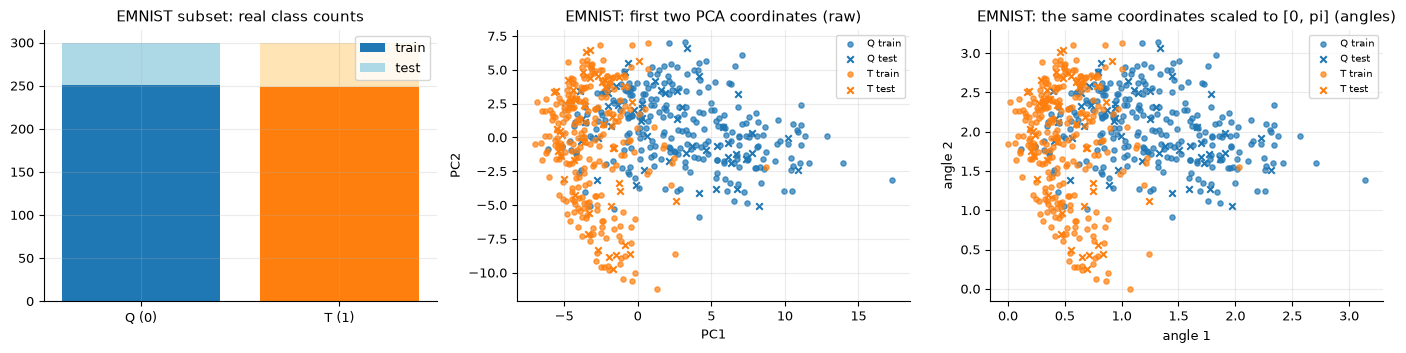

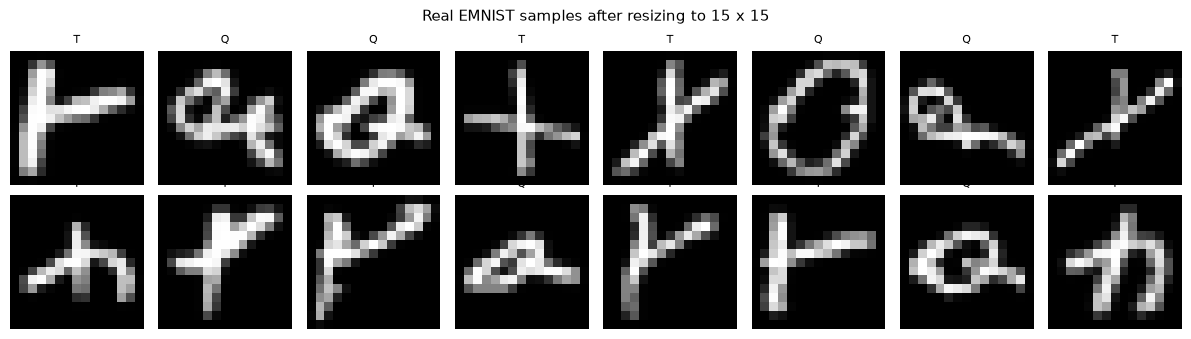

In [7]:
# ---------------- EMNIST Q / T ----------------
names_em = [f"pix_{r}_{c}" for r in range(IMG) for c in range(IMG)]
print("EMNIST Q/T subset: X shape", X_em.shape, "| features:", len(names_em), "(first 5:", names_em[:5], ") | scaled range", float(X_em.min()), "to", round(float(X_em.max()), 3))
print("original labels: HF letter indices", EMNIST_LABELS, "-> 0 = Q, 1 = T | counts (all 600):", {"Q": int((y_em == 0).sum()), "T": int((y_em == 1).sum())})

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].bar(["Q (0)", "T (1)"], [(ytr_em == 0).sum(), (ytr_em == 1).sum()], color=["tab:blue", "tab:orange"], label="train")
ax[0].bar(["Q (0)", "T (1)"], [(yte_em == 0).sum(), (yte_em == 1).sum()], bottom=[(ytr_em == 0).sum(), (ytr_em == 1).sum()], color=["lightblue", "moccasin"], label="test")
ax[0].set_title("EMNIST subset: real class counts"); ax[0].legend()
pca_em = PCA(n_components=2, random_state=SEED).fit(Xtr_em)             # fitted on the training split only
Ztr, Zte = pca_em.transform(Xtr_em), pca_em.transform(Xte_em)
for cls, name, col in ((0, "Q", "tab:blue"), (1, "T", "tab:orange")):
    ax[1].scatter(*Ztr[ytr_em == cls].T, s=14, c=col, alpha=0.7, label=f"{name} train")
    ax[1].scatter(*Zte[yte_em == cls].T, s=22, c=col, marker="x", label=f"{name} test")
ax[1].set_title("EMNIST: first two PCA coordinates (raw)"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend(fontsize=7)
lo, hi = Ztr.min(0), Ztr.max(0)
ang = lambda Z: np.clip((Z - lo) / (hi - lo) * np.pi, 0, np.pi)         # scaler fitted on the training split; test clipped to [0, pi]
Atr, Ate = ang(Ztr), ang(Zte)
for cls, name, col in ((0, "Q", "tab:blue"), (1, "T", "tab:orange")):
    ax[2].scatter(*Atr[ytr_em == cls].T, s=14, c=col, alpha=0.7, label=f"{name} train")
    ax[2].scatter(*Ate[yte_em == cls].T, s=22, c=col, marker="x", label=f"{name} test")
ax[2].set_title("EMNIST: the same coordinates scaled to [0, pi] (angles)"); ax[2].set_xlabel("angle 1"); ax[2].set_ylabel("angle 2"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i in range(16):
    ax.flat[i].imshow(X_em[i].reshape(IMG, IMG) / np.pi, cmap="gray"); ax.flat[i].set_title("Q" if y_em[i] == 0 else "T", fontsize=8); ax.flat[i].axis("off")
plt.suptitle("Real EMNIST samples after resizing to 15 x 15"); plt.tight_layout(); plt.show()

LCEI: X shape (train) (200, 8) | features: ['alpha_0', 'alpha_1', 'alpha_2'] ... (one rotation angle per qubit, all equal for a data point)
original labels: 0 = non-excited (|alpha| < pi/2), 1 = excited | train counts [107  93] test counts [43 57]


state feature matrix (real + imaginary amplitudes): (200, 512)


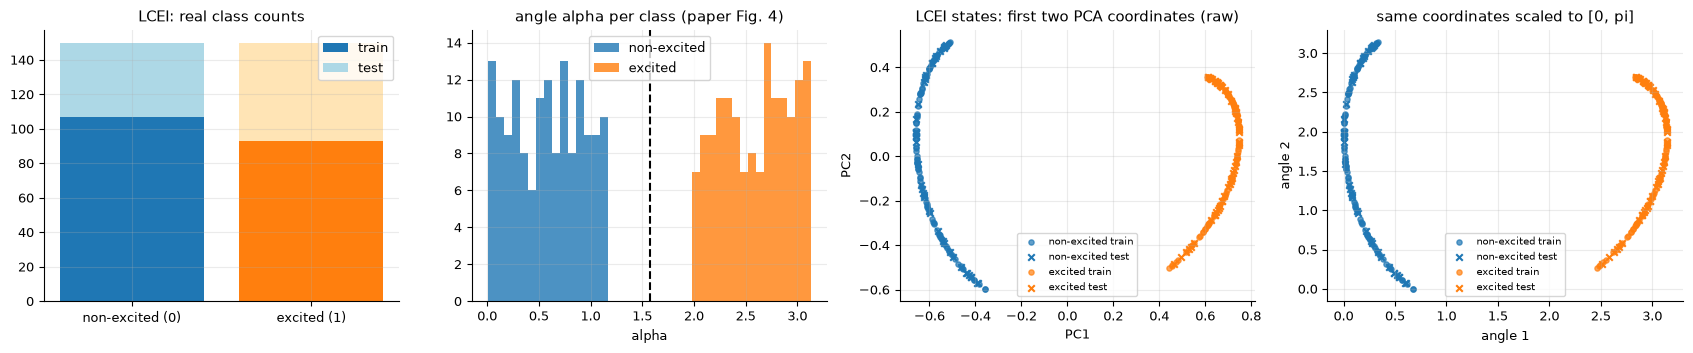

In [8]:
# ---------------- LCEI (needs the cluster-state helper below, defined again in Part 3 for the model) ----------------
def _bits_msb(n):
    return ((torch.arange(2 ** n)[:, None] >> (n - 1 - torch.arange(n)[None])) & 1)
def _cz_signs(n):
    b = _bits_msb(n)
    return (1 - 2 * ((b[:, :-1] * b[:, 1:]).sum(1) % 2)).to(torch.complex128)
def lcei_states(alpha_vec):
    """|psi(alpha)> = prod_i Rx(alpha_i) prod CZ_{i,i+1} |+>^n, batched; alpha_vec: (B, n) tensor."""
    n = alpha_vec.shape[1]; B = alpha_vec.shape[0]
    psi = (_cz_signs(n) / math.sqrt(2 ** n))[None].repeat(B, 1)
    for q in range(n):
        a = alpha_vec[:, q]; c, s = torch.cos(a / 2).to(torch.complex128), torch.sin(a / 2).to(torch.complex128)
        U = torch.stack([torch.stack([c, -1j * s], -1), torch.stack([-1j * s, c], -1)], -2)
        psi = torch.einsum("bij,bljr->blir", U, psi.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))).reshape(B, -1)
    return psi

feat_lc = [f"alpha_{i}" for i in range(N_QUBITS)]
print("LCEI: X shape (train)", Xtr_lc.shape, "| features:", feat_lc[:3], "... (one rotation angle per qubit, all equal for a data point)")
print("original labels: 0 = non-excited (|alpha| < pi/2), 1 = excited | train counts", np.bincount(ytr_lc.astype(int)), "test counts", np.bincount(yte_lc.astype(int)))
S_tr = lcei_states(torch.tensor(Xtr_lc)).numpy(); S_te = lcei_states(torch.tensor(Xte_lc)).numpy()
F_tr = np.concatenate([S_tr.real, S_tr.imag], 1); F_te = np.concatenate([S_te.real, S_te.imag], 1)
print("state feature matrix (real + imaginary amplitudes):", F_tr.shape)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].bar(["non-excited (0)", "excited (1)"], np.bincount(ytr_lc.astype(int)), color=["tab:blue", "tab:orange"], label="train")
ax[0].bar(["non-excited (0)", "excited (1)"], np.bincount(yte_lc.astype(int)), bottom=np.bincount(ytr_lc.astype(int)), color=["lightblue", "moccasin"], label="test")
ax[0].set_title("LCEI: real class counts"); ax[0].legend()
for cls, name, col in ((0, "non-excited", "tab:blue"), (1, "excited", "tab:orange")):
    ax[1].hist(np.r_[Xtr_lc[ytr_lc == cls, 0], Xte_lc[yte_lc == cls, 0]], bins=15, color=col, alpha=0.8, label=name)
ax[1].axvline(np.pi / 2, color="k", ls="--"); ax[1].set_title("angle alpha per class (paper Fig. 4)"); ax[1].set_xlabel("alpha"); ax[1].legend()
pca_lc = PCA(n_components=2, random_state=SEED).fit(F_tr)
Ztr, Zte = pca_lc.transform(F_tr), pca_lc.transform(F_te)
for cls, name, col in ((0, "non-excited", "tab:blue"), (1, "excited", "tab:orange")):
    ax[2].scatter(*Ztr[ytr_lc == cls].T, s=14, c=col, alpha=0.7, label=f"{name} train"); ax[2].scatter(*Zte[yte_lc == cls].T, s=22, c=col, marker="x", label=f"{name} test")
ax[2].set_title("LCEI states: first two PCA coordinates (raw)"); ax[2].set_xlabel("PC1"); ax[2].set_ylabel("PC2"); ax[2].legend(fontsize=7)
lo, hi = Ztr.min(0), Ztr.max(0); ang = lambda Z: np.clip((Z - lo) / (hi - lo) * np.pi, 0, np.pi)
Atr, Ate = ang(Ztr), ang(Zte)
for cls, name, col in ((0, "non-excited", "tab:blue"), (1, "excited", "tab:orange")):
    ax[3].scatter(*Atr[ytr_lc == cls].T, s=14, c=col, alpha=0.7, label=f"{name} train"); ax[3].scatter(*Ate[yte_lc == cls].T, s=22, c=col, marker="x", label=f"{name} test")
ax[3].set_title("same coordinates scaled to [0, pi]"); ax[3].set_xlabel("angle 1"); ax[3].set_ylabel("angle 2"); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Part 3. The hardware-efficient QNN classifier (exact simulator)

The classifier of Section 1.6 has three parts (Fig. 1.5b): a state preparation / data encoding, an `l`-layer variational circuit (SU(2) gate on every qubit followed by nearest-neighbour CZ gates) and a measurement of the output qubit; `p = (<sigma_z> + 1)/2` and a threshold at 0.5. We simulate it **exactly** with a small batched state-vector simulator written in PyTorch (so that gradients with respect to the *input features* are available for Mask-FGSM and with respect to the parameters for training). The notebook asserts below that this simulator reproduces the output of the equivalent PennyLane `QNode` to machine precision, and the circuit that is drawn in the next section is that `QNode`.

* `p1 = Pr(|1>)` on the output qubit (qubit 0) is the probability of class 1 (T, or excited); the paper's `p` is `1 - p1`, the bound is symmetric in the two.
* `rho_out` is the exact reduced density matrix of the output qubit; its fidelity distance between a clean and a perturbed input plays the role of the quantum-state-tomography estimate on the chip.

In [9]:
torch.set_default_dtype(torch.float64)
CDT = torch.complex128
CZ_SIGNS = {}
def cz_signs(n):
    if n not in CZ_SIGNS:
        CZ_SIGNS[n] = _cz_signs(n)
    return CZ_SIGNS[n]

def rot_mats(phi, theta, omega):
    """PennyLane Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi), batched (B,) -> (B, 2, 2)."""
    c, s = torch.cos(theta / 2).to(CDT), torch.sin(theta / 2).to(CDT)
    e = lambda a: torch.exp(1j * a)
    return torch.stack([torch.stack([e(-(phi + omega) / 2) * c, -e((phi - omega) / 2) * s], -1),
                        torch.stack([e(-(phi - omega) / 2) * s, e((phi + omega) / 2) * c], -1)], -2)

def apply_1q(psi, U, q, n):
    """Apply a (B, 2, 2) single-qubit gate to qubit q (qubit 0 = most significant bit) of the batch of states (B, 2^n)."""
    B = psi.shape[0]
    return torch.matmul(U[:, None], psi.reshape(B, 2 ** q, 2, 2 ** (n - q - 1))).reshape(B, -1)

def run_variational(psi, theta, n, L):
    """theta: (B, L, n, 3).  Each layer: Rot on every qubit, then the CZ chain on (0,1), (1,2), ..., (n-2,n-1)."""
    U_all = rot_mats(theta[..., 0], theta[..., 1], theta[..., 2])          # (B, L, n, 2, 2), one vectorised call
    for l in range(L):
        for q in range(n):
            psi = apply_1q(psi, U_all[:, l, q], q, n)
        psi = psi * cz_signs(n)
    return psi

def reduced_out(psi):
    """Reduced density matrix of qubit 0 (the output qubit), shape (B, 2, 2)."""
    s = psi.reshape(psi.shape[0], 2, -1)
    return torch.einsum("bik,bjk->bij", s, s.conj())

class QNN:
    """kind = 'emnist': pixels enter the gate angles (theta_g = w_g + s_g x_(g mod n_x)), input = image vector.
       kind = 'lcei'  : input = per-qubit angles alpha_i of the cluster-state preparation, theta_g = w_g (trainable only)."""
    def __init__(self, kind, n, L, nx=None, seed=SEED):
        self.kind, self.n, self.L = kind, n, L
        g = torch.Generator().manual_seed(seed)
        self.W = (torch.rand(L, n, 3, generator=g) * 2 * math.pi).requires_grad_(True)
        self.S = torch.randn(L, n, 3, generator=g).requires_grad_(True) if kind == "emnist" else None
        self.idx = torch.arange(L * n * 3) % nx if kind == "emnist" else None   # CHOICE: gate g carries pixel g mod n_x
        self.range = math.pi                                                     # x_max - x_min of the data
        self.depol = 0.0                                                         # optional readout depolarising noise
    def params(self):
        return [self.W] + ([self.S] if self.S is not None else [])
    def state(self, x):
        B = x.shape[0]
        if self.kind == "emnist":
            theta = self.W[None] + self.S[None] * x[:, self.idx].reshape(B, self.L, self.n, 3)
            psi0 = torch.zeros(B, 2 ** self.n, dtype=CDT); psi0[:, 0] = 1
        else:
            theta = self.W[None].expand(B, -1, -1, -1)
            psi0 = lcei_states(x)
        return run_variational(psi0, theta, self.n, self.L), theta
    def rho(self, x):
        r = reduced_out(self.state(x)[0])
        return (1 - self.depol) * r + self.depol * torch.eye(2, dtype=CDT) / 2 if self.depol else r
    def p1(self, x):
        return self.rho(x)[:, 1, 1].real
    def copy_from(self, other):
        with torch.no_grad():
            self.W.copy_(other.W)
            if self.S is not None: self.S.copy_(other.S)

def bce(p, y):
    p = p * (1 - 2e-7) + 1e-7                      # keeps the gradient alive even for saturated outputs
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p))

def accuracy(model, X, y):
    with torch.no_grad():
        return float(((model.p1(torch.as_tensor(X)) > 0.5).double() == torch.as_tensor(y)).double().mean())

def input_grad(model, X, y):
    X = X.clone().requires_grad_(True)
    loss = bce(model.p1(X), y).sum()
    return torch.autograd.grad(loss, X)[0]

def train(model, Xtr, ytr, Xte, yte, epochs, lr, batch=BATCH, seed=SEED, adv=None, tag=""):
    """Adam on binary cross-entropy.  adv = (Xadv, yadv): each mini-batch is 50% legitimate + 50% adversarial (paper)."""
    Xtr, ytr, Xte, yte = (torch.as_tensor(a) for a in (Xtr, ytr, Xte, yte))
    opt = torch.optim.Adam(model.params(), lr=lr); g = torch.Generator().manual_seed(seed)
    hist = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr), generator=g); tot = 0.0
        step = batch // 2 if adv is not None else batch
        for i in range(0, len(Xtr), step):
            b = perm[i:i + step]; xb, yb = Xtr[b], ytr[b]
            if adv is not None:
                ia = torch.randint(0, len(adv[0]), (len(b),), generator=g)
                xb, yb = torch.cat([xb, adv[0][ia]]), torch.cat([yb, adv[1][ia]])
            loss = bce(model.p1(xb), yb).mean(); opt.zero_grad(); loss.backward(); opt.step(); tot += float(loss) * len(b)
        rec = dict(epoch=ep + 1, loss=tot / len(Xtr), train_acc=accuracy(model, Xtr, ytr), test_acc=accuracy(model, Xte, yte))
        if adv is not None:
            rec["adv_acc"] = accuracy(model, adv[0], adv[1])
        hist.append(rec)
        if ep == 0 or (ep + 1) % max(1, epochs // 5) == 0 or ep == epochs - 1:
            print(f"[{tag}] epoch {ep + 1:3d}/{epochs}  loss {rec['loss']:.4f}  train {rec['train_acc']:.3f}  test {rec['test_acc']:.3f}" + (f"  adv {rec['adv_acc']:.3f}" if adv is not None else "") + f"  ({time.time() - T0:.0f}s)", flush=True)
    return pd.DataFrame(hist)
print("simulator ready")

simulator ready


## Quantum Circuit Architecture

Two distinct gate-based architectures are trained and evaluated (plus the VeriQR circuit of Part 5, drawn there). Each is drawn from the PennyLane `QNode` that implements exactly the gates of the simulator; an assertion below compares the `QNode` output with the simulator on real samples, so the drawing is the circuit that is executed.

* **EMNIST QNN**: no separate state preparation; every one of the `3 n L` rotation angles of the `Rot` gates is `w_g + s_g x_(g mod 225)`, i.e. the image is encoded in the gate angles (re-uploading style, "interleaved block encoding" of the paper), followed after each layer by the nearest-neighbour CZ chain; output: `<Z>` of qubit 0.
* **LCEI QNN**: Hadamard layer, CZ chain (the cluster state), `R_x(alpha_i)` on each qubit (the data), then the variational layers with free angles; output: `<Z>` of qubit 0.

**Assumptions where the chapter is silent** (the supplementary material of the source experiment is not part of the chapter): 8 qubits instead of 20, 10 / 6 layers instead of 40, one pixel per gate angle with a trainable offset and scale, qubit 0 as the output qubit, the CZ chain applied in order `(0,1), (1,2), ...` after every layer (CZ gates commute, so the order is irrelevant).

EMNIST  simulator p1: [0.48848745 0.63503122 0.63481163] | QNode p1: [0.48848745 0.63503122 0.63481163]


LCEI    simulator p1: [0.53136152 0.50189402 0.5385962 ] | QNode p1: [0.53136152 0.50189402 0.5385962 ]
simulator == PennyLane QNode (atol 1e-10) for both architectures
            qubits  depth  gate_angles  trainable_parameters
EMNIST QNN       8     35          240                   480
LCEI QNN         8     27          144                   144
(EMNIST trainable parameters = offsets w_g + scales s_g for every rotation angle; LCEI = the free rotation angles)


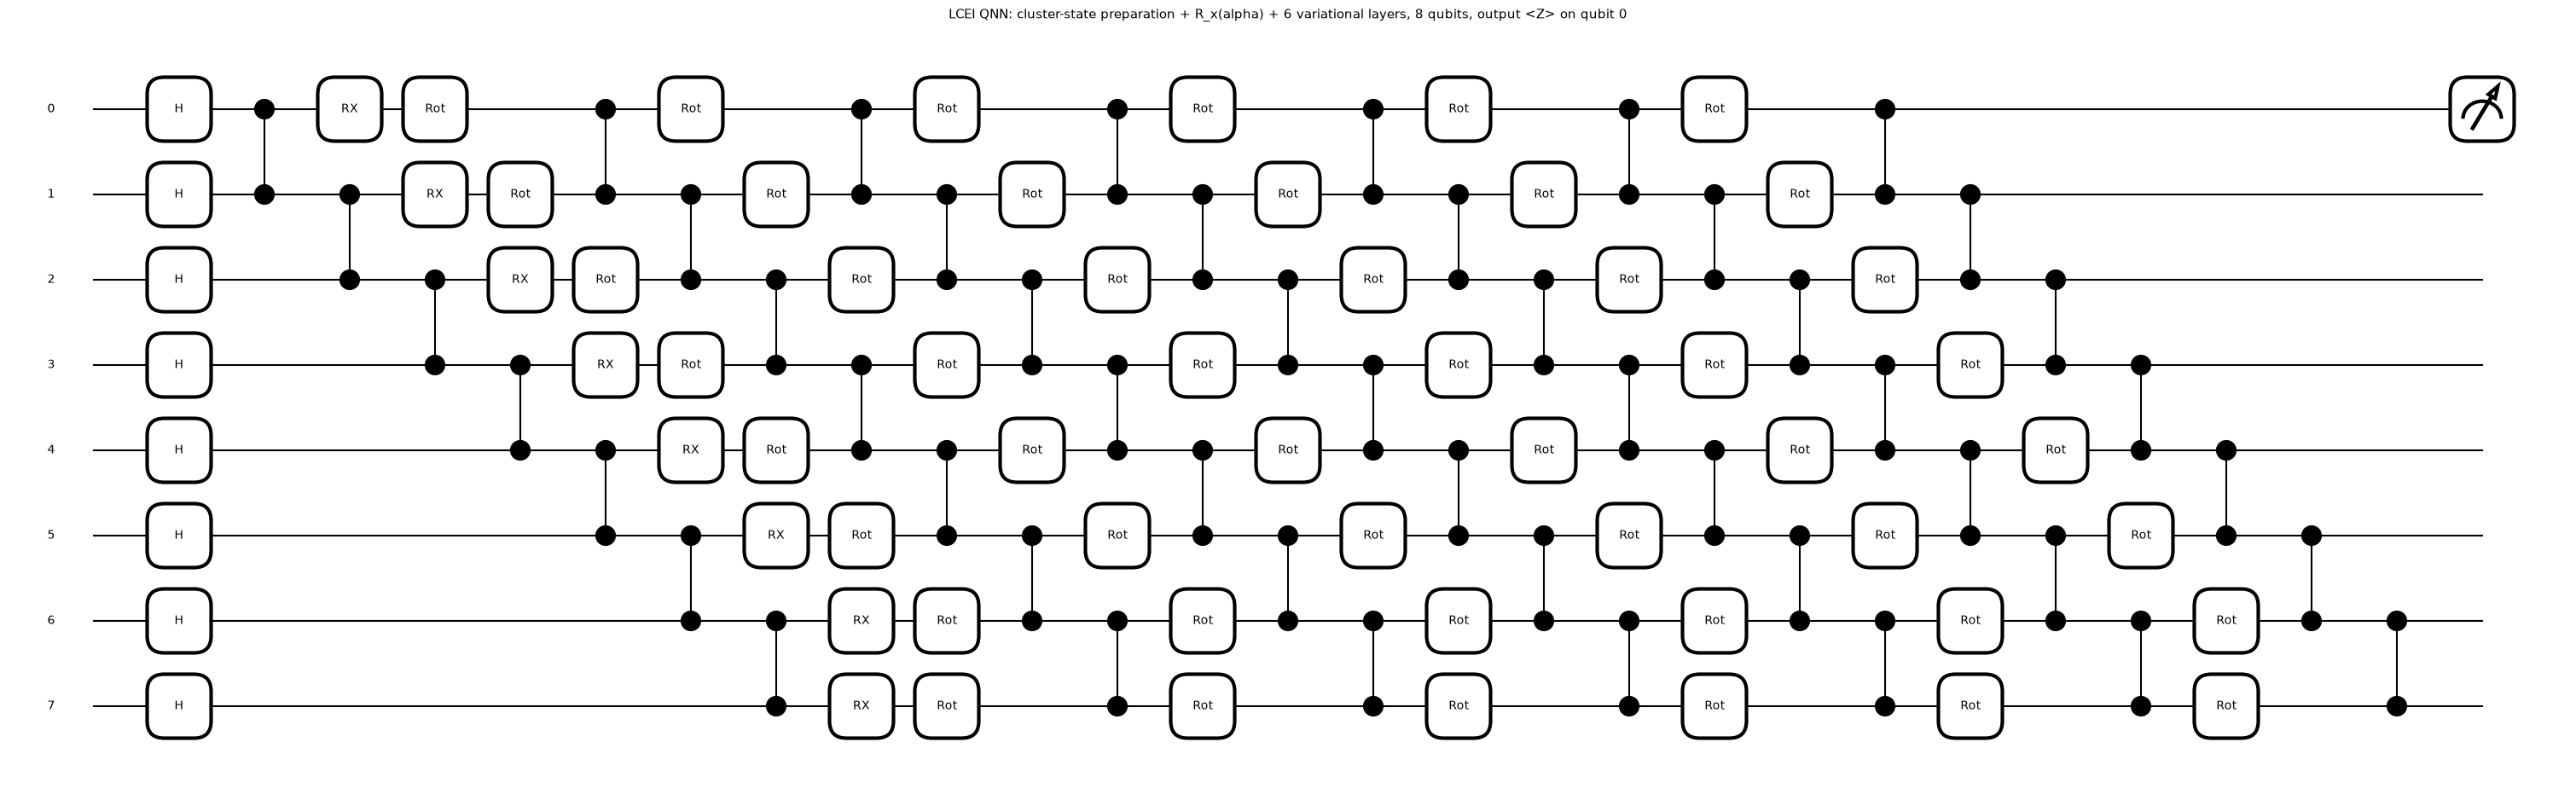

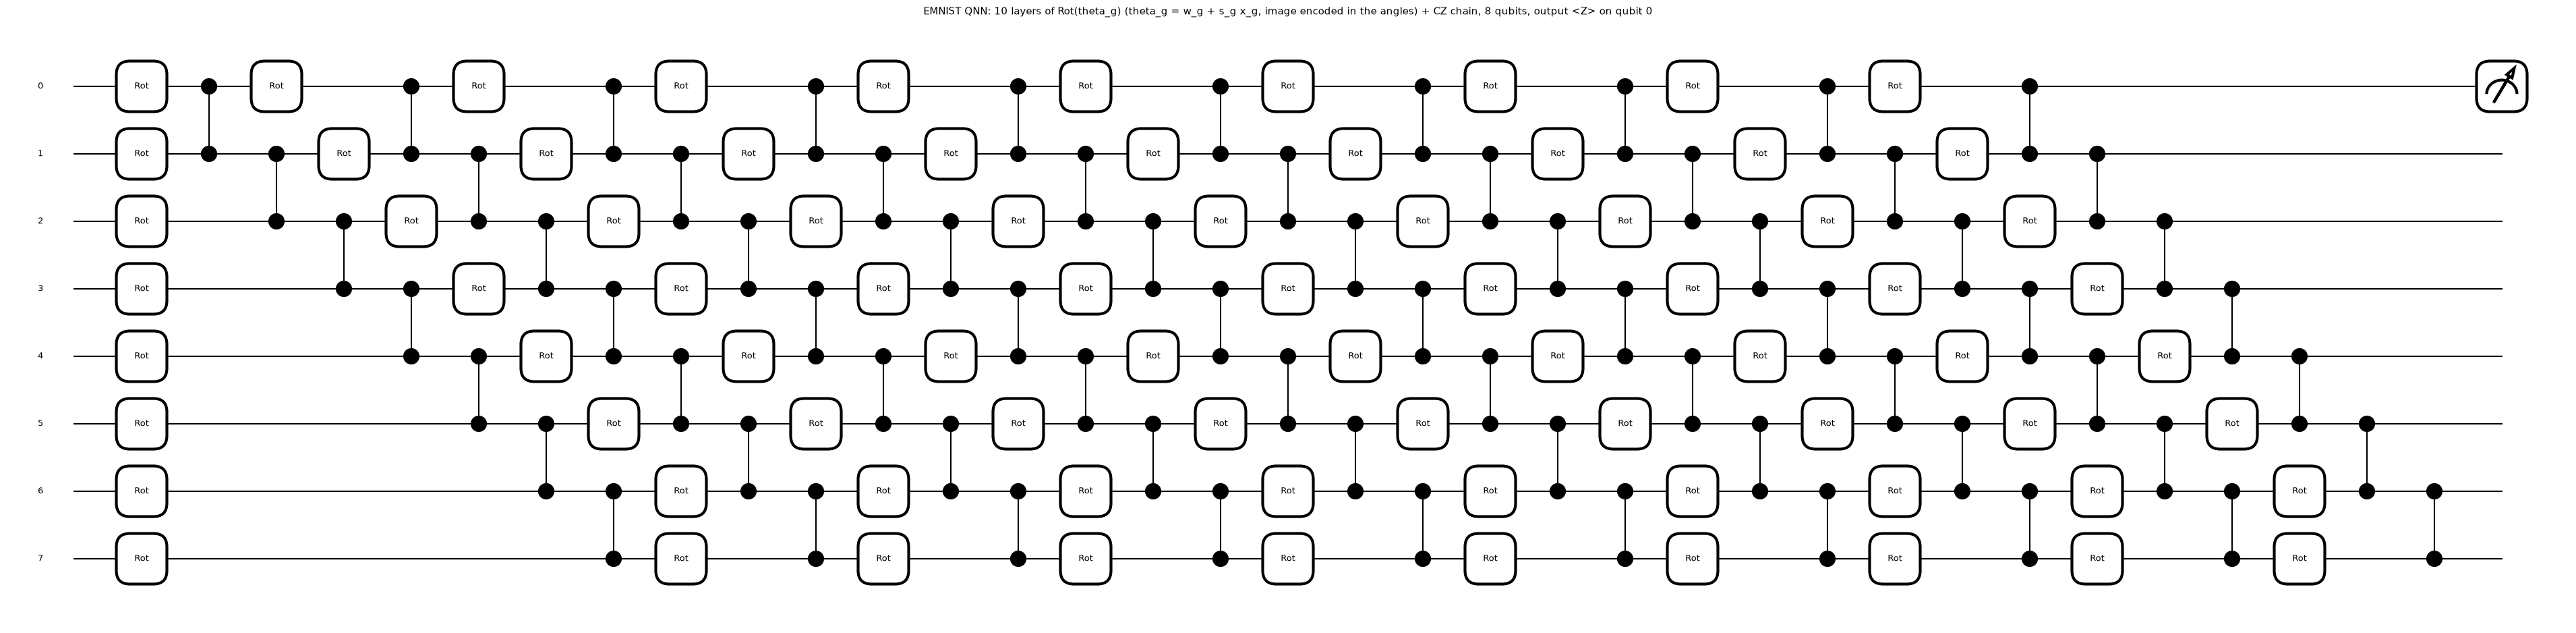

In [10]:
def pl_qnode(kind, n, L):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev)
    def circuit(theta, alpha):
        if kind == "lcei":
            for q in range(n): qml.Hadamard(wires=q)
            for q in range(n - 1): qml.CZ(wires=[q, q + 1])
            for q in range(n): qml.RX(alpha[q], wires=q)
        for l in range(L):
            for q in range(n):
                qml.Rot(theta[l, q, 0], theta[l, q, 1], theta[l, q, 2], wires=q)
            for q in range(n - 1):
                qml.CZ(wires=[q, q + 1])
        return qml.expval(qml.PauliZ(0))
    return circuit

# ---- build the two models (untrained for now) and check the simulator against the QNodes on REAL samples
mdl_em = QNN("emnist", N_QUBITS, L_EMNIST, nx=IMG * IMG)
mdl_lc = QNN("lcei", N_QUBITS, L_LCEI)
qn_em, qn_lc = pl_qnode("emnist", N_QUBITS, L_EMNIST), pl_qnode("lcei", N_QUBITS, L_LCEI)

xs = torch.as_tensor(Xte_em[:3])
with torch.no_grad():
    psi_e, theta_e = mdl_em.state(xs)
    p_sim = mdl_em.p1(xs).numpy()
p_qn = np.array([(1 - float(qn_em(theta_e[i].detach().numpy(), np.zeros(N_QUBITS)))) / 2 for i in range(3)])
print("EMNIST  simulator p1:", np.round(p_sim, 10), "| QNode p1:", np.round(p_qn, 10))
assert np.allclose(p_sim, p_qn, atol=1e-10)
xl = torch.as_tensor(Xte_lc[:3])
with torch.no_grad():
    p_sim = mdl_lc.p1(xl).numpy()
th_l = mdl_lc.W.detach().numpy()
p_qn = np.array([(1 - float(qn_lc(th_l, Xte_lc[i]))) / 2 for i in range(3)])
print("LCEI    simulator p1:", np.round(p_sim, 10), "| QNode p1:", np.round(p_qn, 10))
assert np.allclose(p_sim, p_qn, atol=1e-10)
print("simulator == PennyLane QNode (atol 1e-10) for both architectures")

specs = {}
for name, qn, args, npar in (("EMNIST QNN", qn_em, (theta_e[0].detach().numpy(), np.zeros(N_QUBITS)), 2 * 3 * N_QUBITS * L_EMNIST),
                             ("LCEI QNN", qn_lc, (th_l, Xte_lc[0]), 3 * N_QUBITS * L_LCEI)):
    sp = qml.specs(qn)(*args)
    res = sp["resources"] if isinstance(sp, dict) else sp.resources
    depth = res["depth"] if isinstance(res, dict) else res.depth
    specs[name] = dict(qubits=N_QUBITS, depth=depth, gate_angles=3 * N_QUBITS * (L_EMNIST if "EMNIST" in name else L_LCEI), trainable_parameters=npar)
print(pd.DataFrame(specs).T.to_string())
print("(EMNIST trainable parameters = offsets w_g + scales s_g for every rotation angle; LCEI = the free rotation angles)")

fig, ax = qml.draw_mpl(qn_lc, decimals=None, fontsize=10)(th_l, Xte_lc[0])
fig.suptitle(f"LCEI QNN: cluster-state preparation + R_x(alpha) + {L_LCEI} variational layers, {N_QUBITS} qubits, output <Z> on qubit 0", y=1.02)
plt.show()
fig, ax = qml.draw_mpl(qn_em, decimals=None, fontsize=9)(theta_e[0].detach().numpy(), np.zeros(N_QUBITS))
fig.suptitle(f"EMNIST QNN: {L_EMNIST} layers of Rot(theta_g) (theta_g = w_g + s_g x_g, image encoded in the angles) + CZ chain, {N_QUBITS} qubits, output <Z> on qubit 0", y=1.02)
plt.show()

### Clean training

Adam, mini-batches of 50, binary cross-entropy on `p`. Training accuracies, test accuracies and the loss are recorded every epoch (the analogue of Fig. 5a, b of the source experiment).

[EMNIST clean] epoch   1/60  loss 0.6622  train 0.746  test 0.690  (87s)


[EMNIST clean] epoch  12/60  loss 0.3591  train 0.870  test 0.800  (151s)


[EMNIST clean] epoch  24/60  loss 0.3195  train 0.892  test 0.860  (220s)


[EMNIST clean] epoch  36/60  loss 0.3121  train 0.900  test 0.860  (278s)


[EMNIST clean] epoch  48/60  loss 0.3011  train 0.892  test 0.880  (334s)


...

[LCEI clean] epoch  40/100  loss 0.0636  train 1.000  test 1.000  (500s)


[LCEI clean] epoch  60/100  loss 0.0561  train 1.000  test 1.000  (546s)


[LCEI clean] epoch  80/100  loss 0.0562  train 1.000  test 1.000  (598s)


[LCEI clean] epoch 100/100  loss 0.0560  train 1.000  test 1.000  (643s)


LCEI clean: train 1.000, test 1.000  (237s)


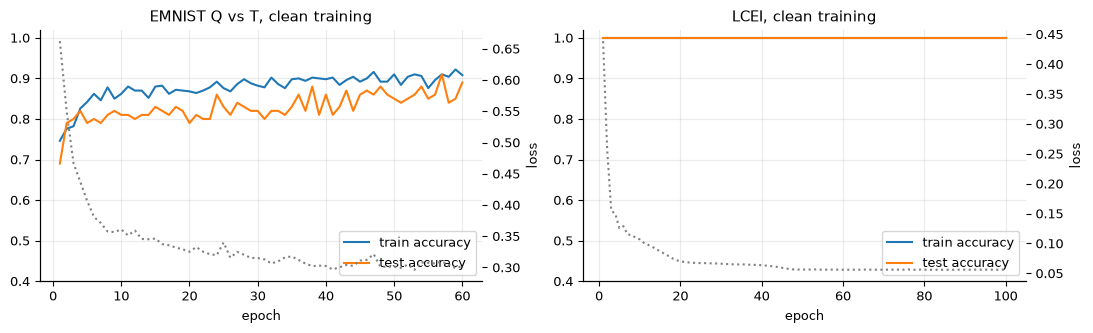

In [11]:
RES.setdefault("acc", {})
mdl_em = QNN("emnist", N_QUBITS, L_EMNIST, nx=IMG * IMG)
t1 = time.time()
Xtr_em_t, Xte_em_t = torch.as_tensor(Xtr_em), torch.as_tensor(Xte_em)
ytr_em_t, yte_em_t = torch.as_tensor(ytr_em), torch.as_tensor(yte_em)
hist_em = train(mdl_em, Xtr_em, ytr_em, Xte_em, yte_em, EPOCHS_CLEAN["emnist"], LR, tag="EMNIST clean")
RES["acc"]["emnist_clean_train"], RES["acc"]["emnist_clean_test"] = hist_em.train_acc.iloc[-1], hist_em.test_acc.iloc[-1]
print(f"EMNIST clean: train {RES['acc']['emnist_clean_train']:.3f}, test {RES['acc']['emnist_clean_test']:.3f}  ({time.time() - t1:.0f}s)")

mdl_lc = QNN("lcei", N_QUBITS, L_LCEI)
t1 = time.time()
Xtr_lc_t, Xte_lc_t = torch.as_tensor(Xtr_lc), torch.as_tensor(Xte_lc)
ytr_lc_t, yte_lc_t = torch.as_tensor(ytr_lc), torch.as_tensor(yte_lc)
hist_lc = train(mdl_lc, Xtr_lc, ytr_lc, Xte_lc, yte_lc, EPOCHS_CLEAN["lcei"], LR, tag="LCEI clean")
RES["acc"]["lcei_clean_train"], RES["acc"]["lcei_clean_test"] = hist_lc.train_acc.iloc[-1], hist_lc.test_acc.iloc[-1]
print(f"LCEI clean: train {RES['acc']['lcei_clean_train']:.3f}, test {RES['acc']['lcei_clean_test']:.3f}  ({time.time() - t1:.0f}s)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, h, t in ((ax[0], hist_em, "EMNIST Q vs T, clean training"), (ax[1], hist_lc, "LCEI, clean training")):
    a.plot(h.epoch, h.train_acc, label="train accuracy"); a.plot(h.epoch, h.test_acc, label="test accuracy")
    a2 = a.twinx(); a2.plot(h.epoch, h.loss, color="gray", ls=":", label="loss"); a2.set_ylabel("loss"); a2.grid(False)
    a.set_title(t); a.set_xlabel("epoch"); a.set_ylim(0.4, 1.02); a.legend(loc="lower right")
plt.tight_layout(); plt.show()

## Part 4. Certified lower bound, Mask-FGSM upper bound and the sandwich (Section 1.6)

**Mask construction (Eqs. 1.2, 7, 8 of the source experiment).** The mean absolute input gradient `G = mean_i |grad_x L(x_i)|` is computed on 20 test samples, the coordinates are ranked, and the top `r N_x` form the binary mask `M`. For EMNIST `r = 0.15` (the paper reports that this mask holds `>= 90%` of the L1 gradient norm; we print the share we obtain); for LCEI the mask is the smallest set of qubit angles that covers `>= 90%` of the L1 norm (the paper finds the gradient concentrated on `Q7`-`Q14` of 20 qubits, i.e. the middle of the chain).

**Iterative Mask-FGSM.** `x_{k+1} = x_k + STEP * (x_max - x_min) * sgn(grad_x L(x_k)) * M` until the predicted label flips; a bisection between the last two iterates then locates the decision boundary `p = 0.5` exactly (this replaces the cos^2 fit of the measured `p(eps)` and `D(eps)` curves on the chip). `eps_RUB = D_F(rho_out(x), rho_out(x_boundary))`, the infidelity of the reduced output-qubit states, and `eps_hat* = max_i |delta_i| / (x_max - x_min)` is the normalised strength at the boundary.

**Lower bound.** `eps_RLB = (1/2)(sqrt(p1) - sqrt(p2))^2` from the outcome probability alone (Theorem 2). Because the fidelity of the output states is the same quantity that the bound controls, `eps_RLB <= eps_RUB` must hold for every sample.

In [12]:
def make_mask(model, X, y, r=None, cover=0.9):
    """Binary mask from the mean absolute input gradient (r = fraction of coordinates, else the smallest set covering `cover` of the L1 norm)."""
    G = input_grad(model, torch.as_tensor(X), torch.as_tensor(y)).abs().mean(0)
    order = torch.argsort(G, descending=True); share = (G[order].cumsum(0) / G.sum())
    k = max(1, int(round(r * len(G)))) if r is not None else int((share < cover).sum()) + 1
    mask = torch.zeros_like(G); mask[order[:k]] = 1.0
    return mask, float(share[k - 1]), k

def mask_fgsm_boundary(model, X, y, mask, step=STEP, max_iters=MAX_ITERS, bisect=45):
    """Batched iterative Mask-FGSM; returns the boundary points x_b (p = 0.5), the success flags and the normalised strengths."""
    X = torch.as_tensor(X); y = torch.as_tensor(y); B = len(X)
    with torch.no_grad():
        nominal = model.p1(X) > 0.5
    x_cur = X.clone(); lo = X.clone(); hi = X.clone(); crossed = torch.zeros(B, dtype=torch.bool)
    for it in range(max_iters):
        act = torch.nonzero(~crossed).flatten()                  # only the samples that have not flipped yet
        if len(act) == 0:
            break
        g = input_grad(model, x_cur[act], nominal[act].double())   # ascend the loss of the model's own label (= true label for correct states)
        x_new = x_cur[act] + step * model.range * torch.sign(g) * mask
        with torch.no_grad():
            flipped = (model.p1(x_new) > 0.5) != nominal[act]
        nw = act[flipped]
        lo[nw], hi[nw] = x_cur[nw], x_new[flipped]
        crossed[nw] = True
        x_cur[act[~flipped]] = x_new[~flipped]
    a = torch.zeros(B)                                   # bisection on the segment lo -> hi
    b = torch.ones(B)
    with torch.no_grad():
        for _ in range(bisect):
            mid = (a + b) / 2
            xm = lo + mid[:, None] * (hi - lo)
            flip = (model.p1(xm) > 0.5) != nominal
            b = torch.where(flip, mid, b); a = torch.where(flip, a, mid)
        xb = lo + ((a + b) / 2)[:, None] * (hi - lo)
    eps_hat = ((xb - X).abs().max(1).values) / model.range
    return xb, crossed, eps_hat

def certify_and_attack(model, X, y, mask, label=""):
    """Per sample: p1, eps_RLB (Theorem 2), eps_RUB (Mask-FGSM + output-qubit fidelity), normalised strength, success flag."""
    X = torch.as_tensor(X); y = torch.as_tensor(y)
    with torch.no_grad():
        rho = model.rho(X); p1 = rho[:, 1, 1].real.numpy()
    xb, ok, eps_hat = mask_fgsm_boundary(model, X, y, mask)
    with torch.no_grad():
        D = (1 - fidelity_qubit(rho, model.rho(xb))).numpy()
    df = pd.DataFrame(dict(p1=p1, pred=(p1 > 0.5).astype(int), true=y.numpy().astype(int), eps_RLB=rlb_binary(p1), eps_RUB=np.where(ok.numpy(), D, np.nan),
                           eps_hat=np.where(ok.numpy(), eps_hat.numpy(), np.nan), success=ok.numpy()))
    return df, xb

# ---------------- masks: 20 test samples, as in the paper ----------------
mask_em, share_em, k_em = make_mask(mdl_em, Xte_em[:20], yte_em[:20], r=MASK_R)
mask_lc, share_lc, k_lc = make_mask(mdl_lc, Xte_lc[:20], yte_lc[:20], r=None, cover=0.9)
print(f"EMNIST mask: top {k_em}/{IMG * IMG} pixels ({k_em / (IMG * IMG):.0%}) cover {share_em:.1%} of the mean |gradient| L1 norm (paper: r ~ 0.15, >= 90%)")
print(f"LCEI mask: qubits {sorted(torch.nonzero(mask_lc).flatten().tolist())} ({k_lc}/{N_QUBITS}) cover {share_lc:.1%} (paper: Q7-Q14 of 20, the middle of the chain)")

EMNIST mask: top 34/225 pixels (15%) cover 86.1% of the mean |gradient| L1 norm (paper: r ~ 0.15, >= 90%)
LCEI mask: qubits [1, 2, 3] (3/8) cover 93.9% (paper: Q7-Q14 of 20, the middle of the chain)


### The 10-state benchmark of the paper (5 per class) and the full test set

The paper benchmarks 10 random input states (5 per class) that the classifier gets right. We draw them with `SEED` among the correctly classified test samples, and also evaluate all correctly classified test samples so that the statistics do not rest on 10 points.

In [13]:
def pick_protocol(model, X, y, n_total=N_PROTOCOL, seed=SEED):
    g = np.random.default_rng(seed)
    with torch.no_grad():
        ok = ((model.p1(torch.as_tensor(X)) > 0.5).double() == torch.as_tensor(y)).numpy()
    idx = []
    for c in (0, 1):
        cand = np.where(ok & (y == c))[0]
        idx += list(g.choice(cand, n_total // 2, replace=False))
    return np.array(idx)

RES["bench"] = {}
tasks = {"emnist": (mdl_em, Xte_em, yte_em, mask_em, "EMNIST Q vs T"), "lcei": (mdl_lc, Xte_lc, yte_lc, mask_lc, "LCEI")}
CLEAN = {}
for key, (mdl, X, y, mask, name) in tasks.items():
    t1 = time.time()
    idx10 = pick_protocol(mdl, X, y)
    dfall, _ = certify_and_attack(mdl, X, y, mask)
    dfall["idx"] = np.arange(len(X))
    dfall = dfall[dfall.pred == dfall.true].reset_index(drop=True)             # correctly classified test states
    df10 = dfall[dfall.idx.isin(idx10)].copy()
    CLEAN[key] = dict(all=dfall, ten=df10, idx10=idx10)
    for tag, d in (("10 states", df10), ("all correct test states", dfall)):
        s = d[d.success]
        RES["bench"][(key, tag)] = dict(n=len(d), n_success=len(s), gap=float((s.eps_RUB - s.eps_RLB).mean()), mean_RLB=float(d.eps_RLB.mean()),
                                         mean_RUB=float(s.eps_RUB.mean()), violations=int((s.eps_RLB > s.eps_RUB + 1e-9).sum()), mean_eps_hat=float(s.eps_hat.mean()))
        r = RES["bench"][(key, tag)]
        print(f"{name:14s} [{tag:24s}] n={r['n']:3d} attack success {r['n_success']:3d} | mean eps_RLB {r['mean_RLB']:.3e} | mean eps_RUB {r['mean_RUB']:.3e} | mean gap {r['gap']:.3e} | violations of eps_RLB <= eps_RUB: {r['violations']}")
    print(f"   ({time.time() - t1:.0f}s)")
display(CLEAN["emnist"]["ten"].round(5)); display(CLEAN["lcei"]["ten"].round(5))
assert all(v["violations"] == 0 for v in RES["bench"].values())

EMNIST Q vs T  [10 states               ] n= 10 attack success  10 | mean eps_RLB 1.312e-01 | mean eps_RUB 1.340e-01 | mean gap 2.801e-03 | violations of eps_RLB <= eps_RUB: 0
EMNIST Q vs T  [all correct test states ] n= 89 attack success  89 | mean eps_RLB 1.213e-01 | mean eps_RUB 1.301e-01 | mean gap 8.884e-03 | violations of eps_RLB <= eps_RUB: 0
   (40s)


LCEI           [10 states               ] n= 10 attack success  10 | mean eps_RLB 3.200e-01 | mean eps_RUB 3.201e-01 | mean gap 4.056e-05 | violations of eps_RLB <= eps_RUB: 0
LCEI           [all correct test states ] n=100 attack success 100 | mean eps_RLB 2.995e-01 | mean eps_RUB 2.995e-01 | mean gap 3.775e-05 | violations of eps_RLB <= eps_RUB: 0
   (73s)


,p1,pred,true,eps_RLB,eps_RUB,eps_hat,success,idx
7,0.11634,0,0,0.17937,0.18517,0.02807,True,10
9,0.81260,1,1,0.10977,0.11176,0.01730,True,12
39,0.61758,1,1,0.01402,0.01519,0.00895,True,43
49,0.16302,0,0,0.13061,0.13071,0.02076,True,54
58,0.09622,0,0,0.20511,0.21410,0.03644,True,65
63,0.47183,0,0,0.00079,0.00165,0.00349,True,70
65,0.59893,1,1,0.00989,0.01510,0.00909,True,72
68,0.88335,1,1,0.17900,0.18031,0.02546,True,75
84,0.95076,1,1,0.28364,0.28397,0.02860,True,93
88,0.10008,0,0,0.19989,0.20214,0.02755,True,99


,p1,pred,true,eps_RLB,eps_RUB,eps_hat,success,idx
7,0.01122,0,0,0.39468,0.39477,0.35537,True,7
8,0.97180,1,1,0.33445,0.33445,0.41101,True,8
45,0.01323,0,0,0.38575,0.38580,0.46074,True,45
48,0.97664,1,1,0.34894,0.34895,0.42516,True,48
62,0.07588,0,0,0.23519,0.23524,0.23274,True,62
67,0.01116,0,0,0.39495,0.39505,0.35580,True,67
73,0.79138,1,1,0.09368,0.09368,0.13682,True,73
78,0.95509,1,1,0.29289,0.29294,0.27152,True,78
92,0.97354,1,1,0.33950,0.33951,0.41589,True,92
98,0.01456,0,0,0.38022,0.38026,0.45553,True,98


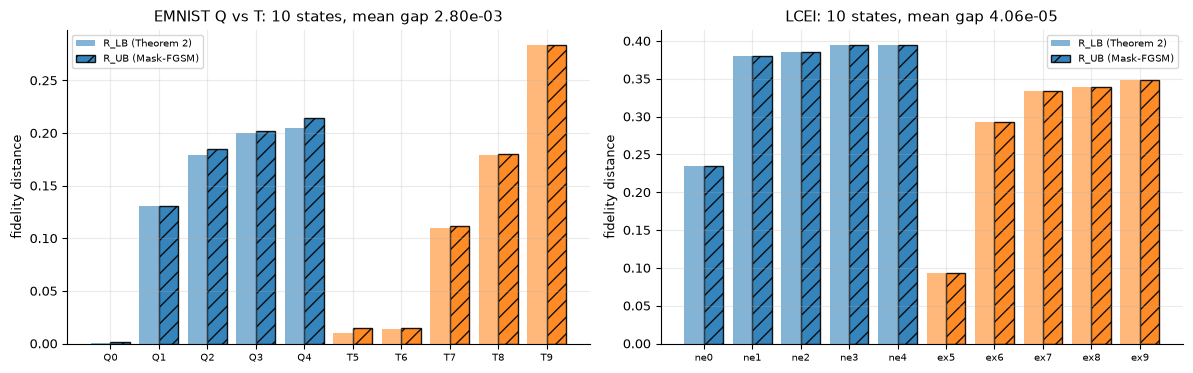

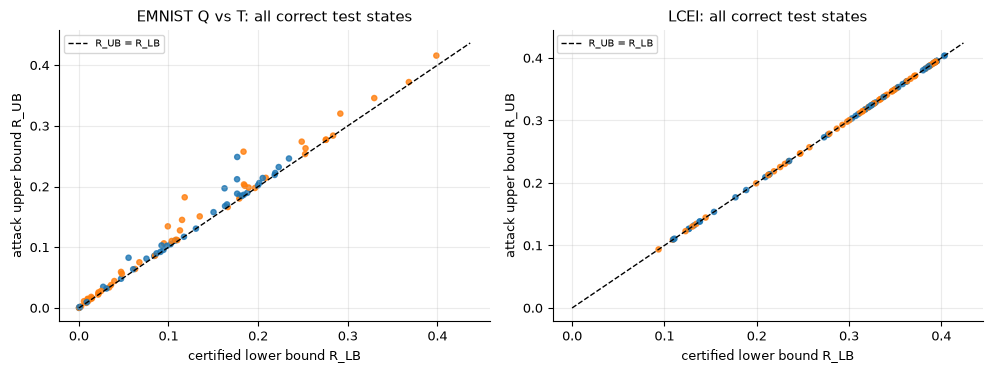

In [14]:
# Re-drawing Fig. 1.6 a, c (upper vs lower bound per sample) and Fig. 1.2 (nested regions)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, key, name in ((ax[0], "emnist", "EMNIST Q vs T"), (ax[1], "lcei", "LCEI")):
    d = CLEAN[key]["ten"].sort_values(["true", "eps_RLB"]).reset_index(drop=True)
    x = np.arange(len(d)); col = np.where(d.true == 0, "tab:blue", "tab:orange")
    a.bar(x - 0.2, d.eps_RLB, 0.4, color=col, alpha=0.55, label="R_LB (Theorem 2)")
    a.bar(x + 0.2, d.eps_RUB, 0.4, color=col, hatch="//", edgecolor="k", alpha=0.9, label="R_UB (Mask-FGSM)")
    a.set_xticks(x); a.set_xticklabels([f"{'Q' if key == 'emnist' else 'ne'}{i}" if t == 0 else f"{'T' if key == 'emnist' else 'ex'}{i}" for i, t in enumerate(d.true)], fontsize=7)
    gap = (d.eps_RUB - d.eps_RLB).mean(); a.set_title(f"{name}: 10 states, mean gap {gap:.2e}"); a.set_ylabel("fidelity distance"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Fig 1.2: every sample is a point (RLB, RUB); the sandwich says RLB <= eps* <= RUB so all points lie above the diagonal
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, key, name in ((ax[0], "emnist", "EMNIST Q vs T"), (ax[1], "lcei", "LCEI")):
    d = CLEAN[key]["all"]; d = d[d.success]
    a.scatter(d.eps_RLB, d.eps_RUB, s=14, c=np.where(d.true == 0, "tab:blue", "tab:orange"), alpha=0.8)
    m = max(d.eps_RLB.max(), d.eps_RUB.max()) * 1.05; a.plot([0, m], [0, m], "k--", lw=1, label="R_UB = R_LB")
    a.set_xlabel("certified lower bound R_LB"); a.set_ylabel("attack upper bound R_UB"); a.set_title(f"{name}: all correct test states"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

### The lower bound needs only measurement statistics (finite shots)

On hardware `p` is estimated from `N = 4096` shots. The bound is a smooth function of `p`, so the shot noise on `p` (standard deviation `sqrt(p(1-p)/N)`) maps to a small error on `eps_RLB`. We estimate `p_hat` by binomial sampling for all correct test states, recompute `eps_RLB` and compare with the exact value and with the attack-based upper bound (the estimated certificate may exceed the true one by a small amount, which is why the paper adds confidence intervals).

In [15]:
gs = np.random.default_rng(SEED + 3)
rows = []
for key in ("emnist", "lcei"):
    d = CLEAN[key]["all"]; d = d[d.success]
    p_hat = gs.binomial(SHOTS, d.p1.values) / SHOTS
    rlb_hat = rlb_binary(p_hat)
    rows.append(dict(task=key, n=len(d), mean_abs_error=float(np.abs(rlb_hat - d.eps_RLB).mean()), rel_error=float((np.abs(rlb_hat - d.eps_RLB) / d.eps_RLB).median()),
                     estimate_above_UB=int((rlb_hat > d.eps_RUB.values).sum())))
print(pd.DataFrame(rows).to_string(index=False))
RES["finite"] = rows

  task   n  mean_abs_error  rel_error  estimate_above_UB
emnist  89        0.003239   0.025744                 21
  lcei 100        0.005200   0.015645                 61


### Adversarial training and its effect on the certificate

As in the source experiment, `N_ADV_TRAIN` adversarial samples (half per class) are generated from *training* states with the masked attack against the clean-trained model, then every training mini-batch consists of 50% legitimate and 50% adversarial samples (with the **correct** labels), starting from the clean weights. We then recompute the certified lower bound on the same states. **Critical samples** are the 20% of the states with the lowest lower bound under clean training; the paper reports that the mean certified bound of these rises by a factor of `4.22` (EMNIST) and `4.74` (LCEI).

In [16]:
def make_adversarial_set(model, X, y, mask, n_total, overshoot=ADV_OVERSHOOT, seed=SEED):
    g = np.random.default_rng(seed)
    with torch.no_grad():
        ok = ((model.p1(torch.as_tensor(X)) > 0.5).double() == torch.as_tensor(y)).numpy()
    idx = np.concatenate([g.permutation(np.where(ok & (y == c))[0])[:n_total // 2] for c in (0, 1)])
    xb, succ, _ = mask_fgsm_boundary(model, X[idx], y[idx], mask)
    x0 = torch.as_tensor(X[idx])
    xadv = x0 + overshoot * (xb - x0)                                         # CHOICE: 20% beyond the boundary
    keep = succ.numpy()
    return xadv[keep].detach(), torch.as_tensor(y[idx][keep]), int(keep.sum())

RES["adv"] = {}
ADV = {}
for key, (mdl, X, y, mask, name) in tasks.items():
    t1 = time.time()
    Xtr_, ytr_, Xte_, yte_ = (Xtr_em, ytr_em, Xte_em, yte_em) if key == "emnist" else (Xtr_lc, ytr_lc, Xte_lc, yte_lc)
    xadv, yadv, nkeep = make_adversarial_set(mdl, Xtr_, ytr_, mask, N_ADV_TRAIN)
    # adversarial TEST samples: boundary points of the CLEAN model for the correctly classified test states (fixed set, used for the 'adversarial accuracy')
    xadv_te, yadv_te, nkeep_te = make_adversarial_set(mdl, Xte_, yte_, mask, 2 * (len(Xte_) // 2))
    with torch.no_grad():
        clean_on_adv = float(((mdl.p1(xadv_te) > 0.5).double() == yadv_te).double().mean())
    print(f"{name}: {nkeep} adversarial training samples kept, {nkeep_te} adversarial test samples | clean model accuracy on the adversarial test set: {clean_on_adv:.3f}")
    adv_mdl = QNN("emnist", N_QUBITS, L_EMNIST, nx=IMG * IMG) if key == "emnist" else QNN("lcei", N_QUBITS, L_LCEI)
    adv_mdl.copy_from(mdl); adv_mdl.depol = mdl.depol
    h = train(adv_mdl, Xtr_, ytr_, Xte_, yte_, EPOCHS_ADV[key], LR_ADV, adv=(xadv, yadv), tag=f"{name} adversarial training")
    with torch.no_grad():
        acc_leg = accuracy(adv_mdl, Xte_, yte_); acc_adv = float(((adv_mdl.p1(xadv_te) > 0.5).double() == yadv_te).double().mean())
    ADV[key] = dict(model=adv_mdl, hist=h, xadv_te=xadv_te, yadv_te=yadv_te, clean_on_adv=clean_on_adv)
    RES["adv"][key] = dict(acc_legit=acc_leg, acc_adv=acc_adv, clean_on_adv=clean_on_adv, n_adv_train=nkeep)
    print(f"{name}: after adversarial training  legitimate test accuracy {acc_leg:.3f} | accuracy on adversarial test samples {acc_adv:.3f}   ({time.time() - t1:.0f}s)")

# ---- certificates of the adversarially trained models on the SAME states
for key, (mdl, X, y, mask, name) in tasks.items():
    adv_mdl = ADV[key]["model"]
    mask_a, share_a, k_a = make_mask(adv_mdl, X[:20], y[:20], r=MASK_R if key == "emnist" else None, cover=0.9)
    dfa, _ = certify_and_attack(adv_mdl, X, y, mask_a)
    dfa["idx"] = np.arange(len(X))
    ADV[key]["all_states"] = dfa
    for tag, ref in (("10 states", CLEAN[key]["ten"]), ("all correct test states", CLEAN[key]["all"])):
        merged = ref[["idx", "eps_RLB", "eps_RUB"]].merge(dfa[["idx", "eps_RLB", "eps_RUB", "pred", "true"]], on="idx", suffixes=("_clean", "_adv"))
        merged = merged.sort_values("eps_RLB_clean").reset_index(drop=True)
        ncrit = max(1, int(round(0.2 * len(merged)))); crit = merged.head(ncrit)
        rec = dict(n=len(merged), n_critical=ncrit, mean_RLB_clean=float(merged.eps_RLB_clean.mean()), mean_RLB_adv=float(merged.eps_RLB_adv.mean()),
                   crit_RLB_clean=float(crit.eps_RLB_clean.mean()), crit_RLB_adv=float(crit.eps_RLB_adv.mean()),
                   factor_all=float(merged.eps_RLB_adv.mean() / merged.eps_RLB_clean.mean()), factor_critical=float(crit.eps_RLB_adv.mean() / crit.eps_RLB_clean.mean()),
                   still_correct=float((merged.pred == merged.true).mean()))
        RES["adv"][(key, tag)] = rec; ADV[key][tag] = merged
        print(f"{name:14s} [{tag:24s}] n={rec['n']:3d} critical={rec['n_critical']:2d} | critical mean eps_RLB {rec['crit_RLB_clean']:.3e} -> {rec['crit_RLB_adv']:.3e}  (factor {rec['factor_critical']:.2f}) | all: factor {rec['factor_all']:.2f} | still correct {rec['still_correct']:.2f}")

EMNIST Q vs T: 200 adversarial training samples kept, 89 adversarial test samples | clean model accuracy on the adversarial test set: 0.000


[EMNIST Q vs T adversarial training] epoch   1/30  loss 0.4018  train 0.848  test 0.800  adv 0.935  (845s)


[EMNIST Q vs T adversarial training] epoch   6/30  loss 0.2567  train 0.886  test 0.820  adv 0.975  (903s)


[EMNIST Q vs T adversarial training] epoch  12/30  loss 0.2401  train 0.906  test 0.830  adv 0.990  (968s)


[EMNIST Q vs T adversarial training] epoch  18/30  loss 0.2373  train 0.910  test 0.820  adv 0.985  (1015s)


...

[LCEI adversarial training] epoch  32/40  loss 0.1860  train 1.000  test 1.000  adv 0.953  (1200s)


[LCEI adversarial training] epoch  40/40  loss 0.1788  train 1.000  test 1.000  adv 0.953  (1210s)


LCEI: after adversarial training  legitimate test accuracy 1.000 | accuracy on adversarial test samples 0.957   (135s)


EMNIST Q vs T  [10 states               ] n= 10 critical= 2 | critical mean eps_RLB 5.340e-03 -> 1.566e-02  (factor 2.93) | all: factor 1.35 | still correct 0.90
EMNIST Q vs T  [all correct test states ] n= 89 critical=18 | critical mean eps_RLB 8.525e-03 -> 3.883e-02  (factor 4.55) | all: factor 1.16 | still correct 0.96


LCEI           [10 states               ] n= 10 critical= 2 | critical mean eps_RLB 1.644e-01 -> 1.227e-01  (factor 0.75) | all: factor 0.62 | still correct 1.00
LCEI           [all correct test states ] n=100 critical=20 | critical mean eps_RLB 1.485e-01 -> 1.067e-01  (factor 0.72) | all: factor 0.61 | still correct 1.00


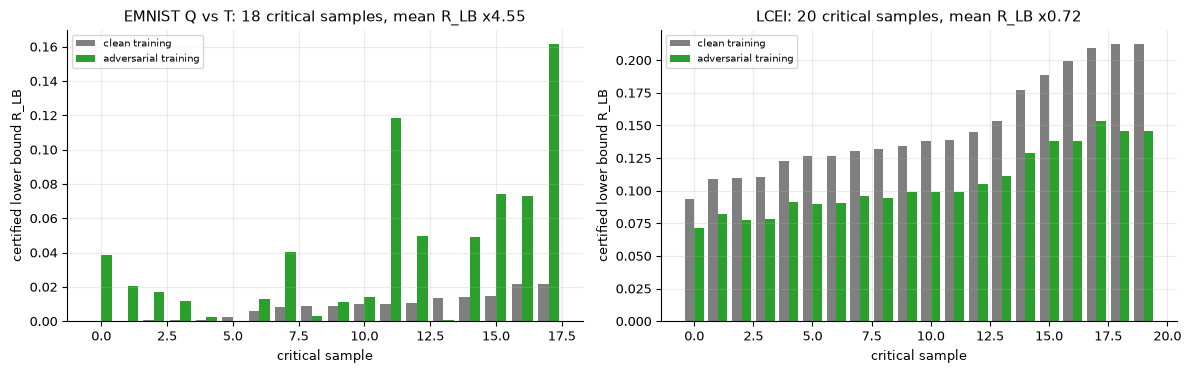

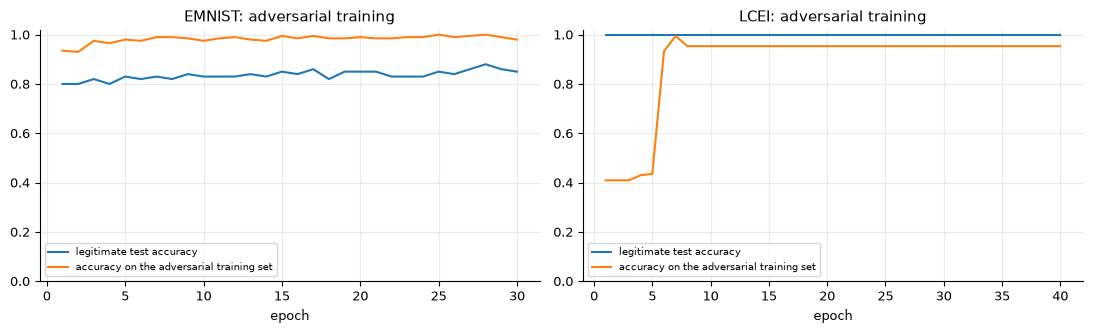

In [17]:
# Re-drawing Fig. 1.6 b, d (certified bounds of the critical samples under clean and adversarial training) + training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, key, name in ((ax[0], "emnist", "EMNIST Q vs T"), (ax[1], "lcei", "LCEI")):
    m = ADV[key]["all correct test states"]; ncrit = max(1, int(round(0.2 * len(m)))); c = m.head(ncrit)
    x = np.arange(len(c))
    a.bar(x - 0.2, c.eps_RLB_clean, 0.4, label="clean training", color="tab:gray"); a.bar(x + 0.2, c.eps_RLB_adv, 0.4, label="adversarial training", color="tab:green")
    r = RES["adv"][(key, "all correct test states")]
    a.set_title(f"{name}: {ncrit} critical samples, mean R_LB x{r['factor_critical']:.2f}"); a.set_xlabel("critical sample"); a.set_ylabel("certified lower bound R_LB"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, key, name in ((ax[0], "emnist", "EMNIST"), (ax[1], "lcei", "LCEI")):
    h = ADV[key]["hist"]
    a.plot(h.epoch, h.test_acc, label="legitimate test accuracy"); a.plot(h.epoch, h.adv_acc, label="accuracy on the adversarial training set")
    a.set_title(f"{name}: adversarial training"); a.set_xlabel("epoch"); a.set_ylim(0.0, 1.02); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## Part 5. The toolchain: Algorithms 2 and 3 on VeriQR's own `mnist01` example

VeriQR takes a model as an OpenQASM 2.0 circuit with a final measurement plus a data file `(O, data, label)`: `O` is the effect of class 1 on the measured qubit, `data` holds one amplitude-encoded state per column (256 amplitudes = 16 x 16 MNIST image, 8 qubits), `label` the digit class (0 or 1 of MNIST). The authors' repository (pinned commit `ee326c0`) ships these files; we download `mnist01.qasm` and `mnist01_data.npz` (2 MB) and re-implement the verification logic from the paper's Algorithms 2 and 3 (our own code; the tool's C++/Qt GUI and its `cvxpy`-based solvers are not used).

* The circuit is parsed with Qiskit and converted to its `256 x 256` unitary. The file does not document its qubit order; the **bit-reversed** order of Qiskit's little-endian convention reproduces the data labels best (87.2%), the other three combinations give 50% to 58%, so that order is used (documented, `# CHOICE:`). The model is a small 8-qubit QNN, so its clean accuracy is not the usual 99% of MNIST 0 vs 1.
* Noise: a single-qubit channel (depolarizing, bit-flip, phase-flip) applied at the end of the circuit on every qubit, exactly VeriQR's "specified noise at the end of the circuit"; in the Heisenberg picture `E*(O)` replaces `O`, and the same `E*(O)` gives the class-1 probability `p = <psi|E*(O)|psi>` and the constraint operator of the SDP.
* **Algorithm 3** ("rough verification"): `eps_RLB` from `p`, a state is certified robust iff `eps <= eps_RLB`; robust accuracy = fraction of the (correctly classified) states certified. **Algorithm 2** ("accurate verification"): same filter, and the exact radius of Theorem 1 only for the states that the filter could not certify.
* Robust accuracy is reported over the correctly classified states `T` (the input set of the algorithms) and over the whole data file (a misclassified state counts as not robust, Definition 6).

In [18]:
vdir = DATA / "veriqr"; vdir.mkdir(exist_ok=True)
def vq_fetch(name):
    f = vdir / name
    if not f.exists():
        url = f"https://raw.githubusercontent.com/Veri-Q/VeriQR/{VERIQR_COMMIT}/py_module/Local/model_and_data/{name}"
        r = requests.get(url, timeout=120); r.raise_for_status(); f.write_bytes(r.content)
    return f
qasm_f, npz_f = vq_fetch("mnist01.qasm"), vq_fetch("mnist01_data.npz")
vd = np.load(npz_f)
O_vq, X_vq, y_vq = vd["O"], vd["data"].astype(float), vd["label"]
print("npz keys:", vd.files, "| O", O_vq.shape, "| data", X_vq.shape, "| label", y_vq.shape)
qc_vq = QuantumCircuit.from_qasm_file(str(qasm_f))
qc_vq_nom = qc_vq.remove_final_measurements(inplace=False)
U_q = Operator(qc_vq_nom).data
rev = np.array([int(format(i, "08b")[::-1], 2) for i in range(256)])
U_vq = U_q[np.ix_(rev, rev)]                                  # CHOICE: bit-reversed order, see the text above
nq = qc_vq.num_qubits
assert U_vq.shape == (256, 256) and np.allclose(U_vq.conj().T @ U_vq, np.eye(256), atol=1e-9)
P_vq = U_vq.conj().T @ O_vq @ U_vq                            # E*(O) without noise
p_vq = np.einsum("ik,ij,jk->k", X_vq, P_vq.real, X_vq)        # class-1 probability of every state
pred_vq = (p_vq > 0.5).astype(int)
print(f"circuit: {nq} qubits, depth {qc_vq.depth()}, gates {dict(qc_vq.count_ops())} | clean accuracy on the 1000 states: {np.mean(pred_vq == y_vq):.3f}")
for name, Uu in (("Qiskit little-endian order", U_q),):
    acc_alt = np.mean((np.einsum("ik,ij,jk->k", X_vq, (Uu.conj().T @ O_vq @ Uu).real, X_vq) > 0.5) == y_vq)
    print(f"   (for comparison, {name}: {acc_alt:.3f})")

npz keys: ['O', 'data', 'label'] | O (256, 256) | data (256, 1000) | label (1000,)


circuit: 8 qubits, depth 36, gates {'rx': 90, 'rz': 45, 'crz': 22, 'measure': 1} | clean accuracy on the 1000 states: 0.872


   (for comparison, Qiskit little-endian order: 0.584)


### Dataset Exploration and Visualisation of the VeriQR `mnist01` data

Same recipe as for the other two datasets: shape, feature description, original labels and counts, class bar chart and PCA scatter coloured by the real label (raw coordinates, then scaled to `[0, pi]`).

VeriQR mnist01: data matrix (states as columns) (256, 1000) -> samples x features (1000, 256) | features = 256 amplitudes (16 x 16 pixels, amplitude encoded)
original labels: {0: 500, 1: 500} (MNIST digits 0 and 1)


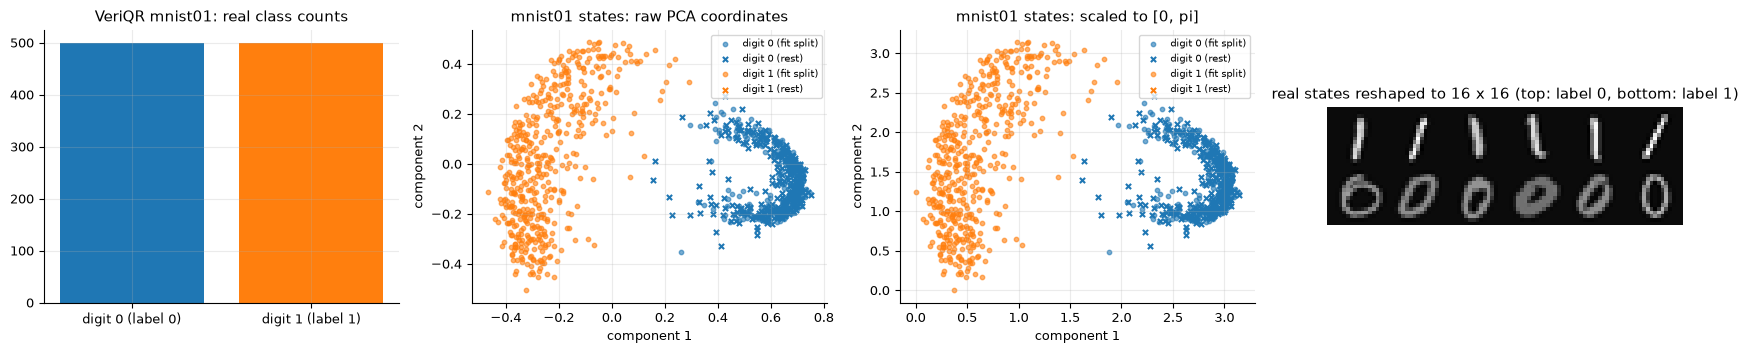

In [19]:
# ---- Dataset exploration of the VeriQR file (same recipe as above)
print("VeriQR mnist01: data matrix (states as columns)", X_vq.shape, "-> samples x features", X_vq.T.shape, "| features = 256 amplitudes (16 x 16 pixels, amplitude encoded)")
print("original labels:", {int(k): int(v) for k, v in zip(*np.unique(y_vq, return_counts=True))}, "(MNIST digits 0 and 1)")
Xs = X_vq.T
tr, te = np.arange(len(Xs)) < 700, np.arange(len(Xs)) >= 700                        # CHOICE: first 700 states = 'training split' for the PCA fit only
pca_vq = PCA(n_components=2, random_state=SEED).fit(Xs[tr]); Z = pca_vq.transform(Xs)
lo, hi = Z[tr].min(0), Z[tr].max(0); A = np.clip((Z - lo) / (hi - lo) * np.pi, 0, np.pi)
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].bar(["digit 0 (label 0)", "digit 1 (label 1)"], np.bincount(y_vq), color=["tab:blue", "tab:orange"]); ax[0].set_title("VeriQR mnist01: real class counts")
for a, M, t in ((ax[1], Z, "raw PCA coordinates"), (ax[2], A, "scaled to [0, pi]")):
    for cls, name, col in ((0, "digit 0", "tab:blue"), (1, "digit 1", "tab:orange")):
        m = y_vq == cls
        a.scatter(*M[m & tr].T, s=10, c=col, alpha=0.6, label=f"{name} (fit split)"); a.scatter(*M[m & te].T, s=14, c=col, marker="x", label=f"{name} (rest)")
    a.set_title(f"mnist01 states: {t}"); a.set_xlabel("component 1"); a.set_ylabel("component 2"); a.legend(fontsize=7)
tile = np.concatenate([np.concatenate([X_vq[:, np.where(y_vq == c)[0][j]].reshape(16, 16) for j in range(6)], 1) for c in (0, 1)], 0)
ax[3].imshow(tile, cmap="gray"); ax[3].axis("off"); ax[3].set_title("real states reshaped to 16 x 16 (top: label 0, bottom: label 1)"); ax[3].grid(False)
plt.tight_layout(); plt.show()

### The verified circuit

The VeriQR classifier is a fixed, already trained circuit stored in OpenQASM; it is drawn exactly as parsed. (Gate-based; the encoding of the input is by amplitude-encoded states supplied in the data file.)

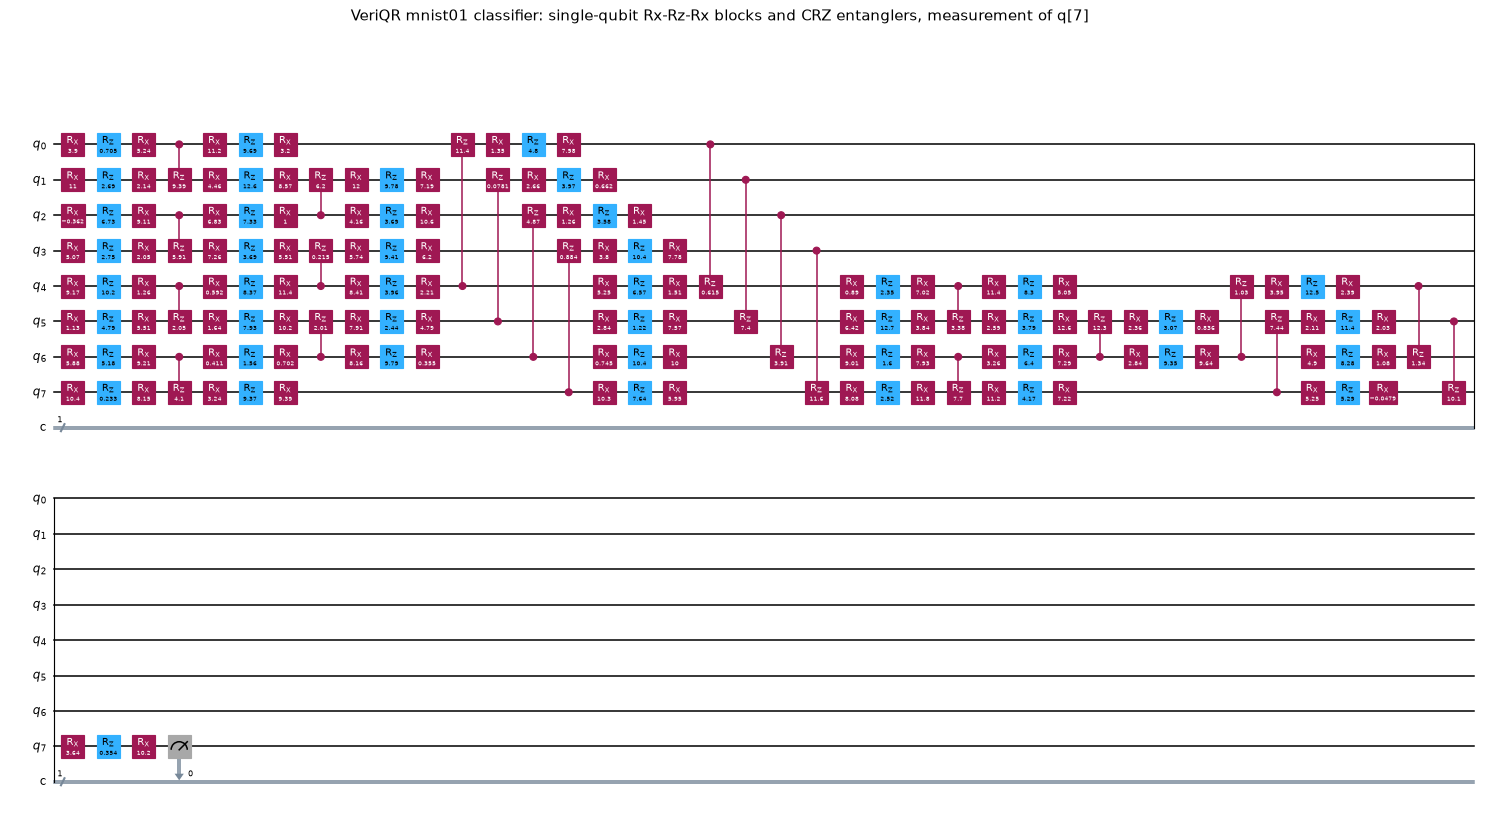

qubits 8 | depth 36 | trainable (fixed, stored) rotation angles 157 | measured qubit: q[7]; inputs are 8-qubit amplitude-encoded pure states (not drawn: they come from the data file)


In [20]:
# ---- the circuit that is verified (the QASM file as loaded: encoding is amplitude-encoded INPUT states, so the drawn circuit is the classifier itself)
fig = qc_vq.draw("mpl", fold=40, scale=0.55)
fig.suptitle("VeriQR mnist01 classifier: single-qubit Rx-Rz-Rx blocks and CRZ entanglers, measurement of q[7]", y=1.0)
display(fig)                                   # Qiskit's figure is not a pyplot figure, so plt.show() would not render it
n_ang = sum(qc_vq.count_ops().get(k, 0) for k in ("rx", "rz", "crz"))
print(f"qubits {qc_vq.num_qubits} | depth {qc_vq.depth()} | trainable (fixed, stored) rotation angles {n_ang} | measured qubit: q[7]; inputs are 8-qubit amplitude-encoded pure states (not drawn: they come from the data file)")

### Algorithms 2 and 3 with noise

In [21]:
import time as _t
def verify_dataset(Pstar, X, y, eps, exact_radii=None):
    """Algorithms 3 (rough) and 2 (accurate) on a binary classifier with class-1 operator Pstar = E*(O)."""
    t0 = _t.perf_counter()
    p1 = np.einsum("ik,ij,jk->k", X, Pstar.real, X)
    pred = (p1 > 0.5).astype(int); correct = pred == y
    lb = rlb_binary(p1)
    certified = correct & (eps <= lb)                              # Algorithm 3: certified by the lower bound
    t_rough = _t.perf_counter() - t0
    cand = np.where(correct & (eps > lb))[0]                       # T' of Table 1.1: states the filter cannot certify
    robust_exact = certified.copy(); t_sdp = 0.0
    for i in cand:
        ts = _t.perf_counter(); r = exact_radii[i](); t_sdp += _t.perf_counter() - ts
        robust_exact[i] = eps <= r
    nT = int(correct.sum())
    return dict(eps=eps, RA_rough_T=certified.sum() / nT, RA_exact_T=robust_exact.sum() / nT, RA_rough_all=certified.sum() / len(y), RA_exact_all=robust_exact.sum() / len(y),
                t_rough=t_rough, t_exact=t_rough + t_sdp, n_candidates=len(cand), n_T=nT)

Nv = N_VERIQR
Xv, yv = X_vq[:, :Nv], y_vq[:Nv]
NOISES = [("noiseless", None, 0.0), ("depolarizing", "depolarizing", 0.05), ("depolarizing", "depolarizing", 0.2), ("bit_flip", "bit_flip", 0.05), ("phase_flip", "phase_flip", 0.05)]
EPS_GRID = [1e-4, 5e-4, 1e-3, 2e-3, 4e-3]
vrows = []
for nname, kind, pr in NOISES:
    Ostar = O_vq.astype(complex) if kind is None else heisenberg_noise(O_vq, nq, kind, pr)
    Pstar = U_vq.conj().T @ Ostar @ U_vq
    p1 = np.einsum("ik,ij,jk->k", Xv, Pstar.real, Xv); pred = (p1 > 0.5).astype(int)
    ev = ExactVerifier(-(2 * Pstar - np.eye(256)))                  # predicted class 0: adversary needs Tr[(2P - I) sigma] >= 0, i.e. Tr[C sigma] <= 0 with C = -(2P - I)
    evn = ExactVerifier(2 * Pstar - np.eye(256))                    # predicted class 1: adversary needs Tr[(2P - I) sigma] <= 0
    radii_cache = {}
    def exact_radius_fn(i, pred=pred, Xv=Xv, ev=ev, evn=evn, cache=radii_cache):
        def f():
            if i not in cache:
                cache[i] = (ev if pred[i] == 0 else evn).radius(Xv[:, i].astype(complex))
            return cache[i]
        return f
    exact_fns = {i: exact_radius_fn(i) for i in range(Nv)}
    for eps in EPS_GRID:
        # time of the exact stage is measured on first use of a state; cached radii are re-timed through a fresh call
        radii_cache.clear()
        r = verify_dataset(Pstar, Xv, yv, eps, exact_fns); r.update(noise=nname, strength=pr); vrows.append(r)
vt = pd.DataFrame(vrows)[["noise", "strength", "eps", "RA_rough_T", "RA_exact_T", "RA_rough_all", "RA_exact_all", "n_candidates", "n_T", "t_rough", "t_exact"]]
print(f"clean accuracy on the first {Nv} states: {np.mean(pred_vq[:Nv] == yv):.3f}")
print(vt.round({"RA_rough_T": 4, "RA_exact_T": 4, "RA_rough_all": 4, "RA_exact_all": 4, "t_rough": 4, "t_exact": 3}).to_string(index=False))
RES["veriqr"] = dict(table=vt, under_ok=bool((vt.RA_rough_T <= vt.RA_exact_T + 1e-12).all()),
                     speedup=float((vt.t_exact / vt.t_rough).median()), cand_frac=float((vt.n_candidates / vt.n_T).median()))
print("Algorithm 3 never above Algorithm 2 (under-approximation):", RES["veriqr"]["under_ok"], "| median time ratio Alg.2 / Alg.3:", round(RES["veriqr"]["speedup"], 1), "| median |T'|/|T|:", round(RES["veriqr"]["cand_frac"], 2))
assert RES["veriqr"]["under_ok"]

clean accuracy on the first 1000 states: 0.872
       noise  strength    eps  RA_rough_T  RA_exact_T  RA_rough_all  RA_exact_all  n_candidates  n_T  t_rough  t_exact
   noiseless      0.00 0.0001      0.8899      0.8899         0.776         0.776            96  872   0.1967    4.435
   noiseless      0.00 0.0005      0.7523      0.7523         0.656         0.656           216  872   0.2430    6.509
   noiseless      0.00 0.0010      0.6433      0.6433         0.561         0.561           311  872   0.1554   14.413
   noiseless      0.00 0.0020      0.4805      0.4805         0.419         0.419           453  872   0.2290   14.191
   noiseless      0.00 0.0040      0.3142      0.3142         0.274         0.274           598  872   0.2778   18.333
depolarizing      0.05 0.0001      0.8830      0.8899         0.770         0.776           102  872   0.2077    4.268
depolarizing      0.05 0.0005      0.7362      0.7523         0.642         0.656           230  872   0.3183   10.346
d

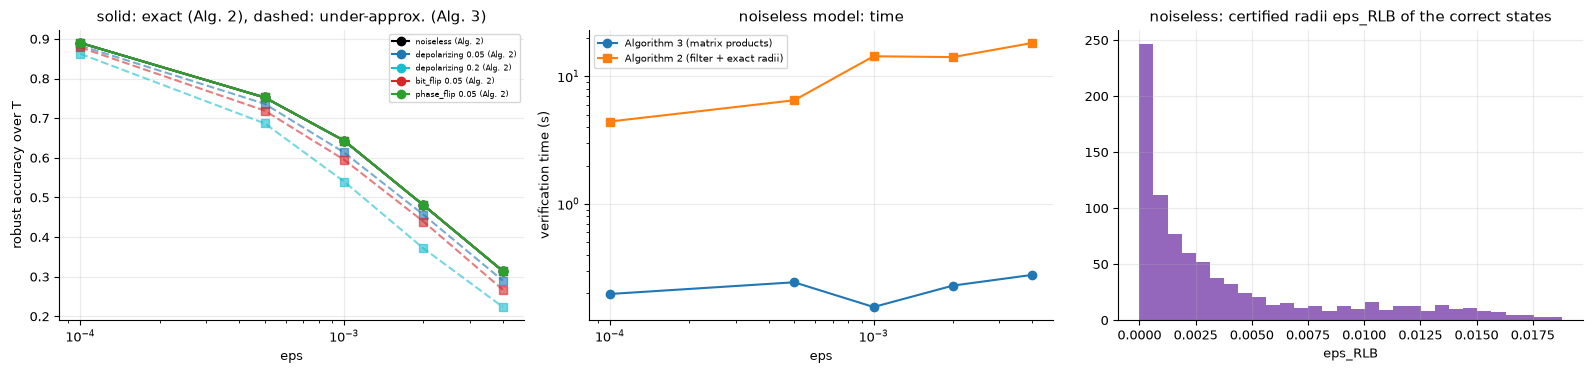

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for (nname, kind, pr), col in zip(NOISES, ["k", "tab:blue", "tab:cyan", "tab:red", "tab:green"]):
    d = vt[(vt.noise == nname) & (vt.strength == pr)]; lab = nname if pr == 0 else f"{nname} {pr}"
    ax[0].plot(d.eps, d.RA_exact_T, "-o", color=col, label=lab + " (Alg. 2)"); ax[0].plot(d.eps, d.RA_rough_T, "--s", color=col, alpha=0.6)
ax[0].set_xscale("log"); ax[0].set_xlabel("eps"); ax[0].set_ylabel("robust accuracy over T"); ax[0].set_title("solid: exact (Alg. 2), dashed: under-approx. (Alg. 3)"); ax[0].legend(fontsize=6)
d = vt[vt.noise == "noiseless"]; ax[1].semilogx(d.eps, d.t_rough, "-o", label="Algorithm 3 (matrix products)"); ax[1].semilogx(d.eps, d.t_exact, "-s", label="Algorithm 2 (filter + exact radii)")
ax[1].set_yscale("log"); ax[1].set_xlabel("eps"); ax[1].set_ylabel("verification time (s)"); ax[1].set_title("noiseless model: time"); ax[1].legend(fontsize=7)
pcs = np.einsum("ik,ij,jk->k", Xv, P_vq.real, Xv)
rl = rlb_binary(pcs)[(pcs > 0.5) == yv]
ax[2].hist(rl, bins=30, color="tab:purple"); ax[2].set_title("noiseless: certified radii eps_RLB of the correct states"); ax[2].set_xlabel("eps_RLB")
plt.tight_layout(); plt.show()

### Table 1.1: cost of the lower bound vs the exact radius

Per input state, the lower bound costs one quadratic form (`O(N^2)` once `E*(O)` is known) while the exact radius costs an eigendecomposition-based optimisation (`O(N^3)` here, `O(N^6.5)` for a generic SDP solver). We time both for random noisy classifiers with `n = 3 ... 8` qubits (`N = 2^n`).

 qubits  dim  t_lower_bound_ms  t_exact_ms     ratio
      3    8             0.006      50.574  8765.005
      4   16             0.005      64.179 13929.186
      5   32             0.011      47.004  4400.132
      6   64             0.114      68.353   599.750
      7  128             0.364      50.151   137.733
      8  256             1.118      63.097    56.430


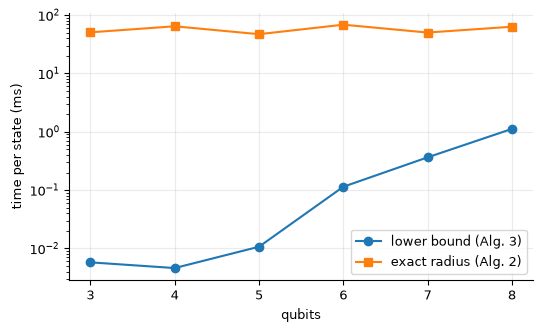

In [23]:
g = np.random.default_rng(SEED + 11)
rows = []
for n in range(3, 9):
    d = 2 ** n
    U = haar_unitary(d, g); M1 = np.kron(np.diag([0.0, 1.0]), np.eye(d // 2)); P = U.conj().T @ heisenberg_noise(M1, n, "depolarizing", 0.1) @ U
    psis = g.normal(size=(d, 40)) + 1j * g.normal(size=(d, 40)); psis /= np.linalg.norm(psis, axis=0)
    t0 = _t.perf_counter(); p1 = np.real(np.einsum("ik,ij,jk->k", psis.conj(), P, psis)); lb = rlb_binary(p1); t_lb = (_t.perf_counter() - t0) / 40
    ev = ExactVerifier(-(2 * P - np.eye(d))); evn = ExactVerifier(2 * P - np.eye(d))     # predicted class 0 / class 1
    t0 = _t.perf_counter()
    for k in range(10):
        (ev if p1[k] < 0.5 else evn).radius(psis[:, k])
    t_ex = (_t.perf_counter() - t0) / 10
    rows.append(dict(qubits=n, dim=d, t_lower_bound_ms=1e3 * t_lb, t_exact_ms=1e3 * t_ex, ratio=t_ex / t_lb))
sc = pd.DataFrame(rows); print(sc.round(3).to_string(index=False)); RES["scaling"] = sc
fig, ax = plt.subplots(figsize=(5.5, 3.4)); ax.semilogy(sc.qubits, sc.t_lower_bound_ms, "-o", label="lower bound (Alg. 3)"); ax.semilogy(sc.qubits, sc.t_exact_ms, "-s", label="exact radius (Alg. 2)")
ax.set_xlabel("qubits"); ax.set_ylabel("time per state (ms)"); ax.legend(); plt.tight_layout(); plt.show()

## Part 6. Side-by-side comparison with the paper

In [24]:
def verdict_ratio(ours, paper, lo=1/3, hi=3.0):
    r = ours / paper
    return "reproduced" if lo <= r <= hi else ("exceeded (our value is smaller by %.1fx)" % (1 / r) if r < lo else "not reached (our value is larger by %.1fx)" % r)
def verdict_abs(ours, paper, tol=0.02):
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded by %.1f points" % (100 * (ours - paper)) if ours > paper else "not reached (%.1f points below)" % (100 * (paper - ours)))
def verdict_factor(ours, paper, tol=0.3):
    return "reproduced" if abs(ours - paper) / paper <= tol else ("exceeded (x%.2f)" % ours if ours > paper else "not reached (x%.2f)" % ours)

B, A_, AC = RES["bench"], RES["adv"], RES["acc"]
rows = []
tot_viol = sum(v["violations"] for v in B.values()) + RES["random_violations"]
rows.append(("eps_RLB <= eps* <= eps_RUB always (Thm 3)", "holds (theorem; hardware: all samples)", f"0 violations needed; found {tot_viol} on {RES['random_n']} random classifiers + {sum(v['n_success'] for v in B.values())} attacked states", "reproduced" if tot_viol == 0 else "NOT reproduced"))
rows.append(("Thm 1: SDP radius attained / Thm 2 exact without noise", "stated", f"dual attained by a pure state in {RES['dual_attained_frac']:.0%} of the random instances", "reproduced" if RES["dual_attained_frac"] > 0.95 else "partially"))
for key, nm, pg in (("emnist", "EMNIST", 2.96e-3), ("lcei", "LCEI", 3.25e-3)):
    g10, gall = B[(key, "10 states")]["gap"], B[(key, "all correct test states")]["gap"]
    rows.append((f"Mean gap R_UB - R_LB, {nm}, 10 states", f"{pg:.2e} (20-qubit hardware)", f"{g10:.2e} (all correct test states: {gall:.2e}; 8-qubit noiseless simulation)", verdict_ratio(g10, pg)))
for key, nm, pf in (("emnist", "EMNIST", 4.22), ("lcei", "LCEI", 4.74)):
    f10, fall = A_[(key, "10 states")]["factor_critical"], A_[(key, "all correct test states")]["factor_critical"]
    rows.append((f"Adversarial training: x increase of the mean R_LB of critical samples, {nm}", f"x{pf} (hardware, 2 critical samples)", f"x{f10:.2f} on the 10-state protocol ({A_[(key, '10 states')]['n_critical']} critical); x{fall:.2f} on all correct test states ({A_[(key, 'all correct test states')]['n_critical']} critical)", verdict_factor(f10, pf)))
rows.append(("Clean test accuracy, EMNIST Q/T", "96% (source experiment)", f"{AC['emnist_clean_test']:.1%} (train {AC['emnist_clean_train']:.1%})", verdict_abs(AC["emnist_clean_test"], 0.96)))
rows.append(("Clean test accuracy, LCEI", "100%", f"{AC['lcei_clean_test']:.1%}", verdict_abs(AC["lcei_clean_test"], 1.0)))
rows.append(("After adversarial training: legitimate / adversarial accuracy, EMNIST", "88% / 87% (source experiment)", f"{A_['emnist']['acc_legit']:.1%} / {A_['emnist']['acc_adv']:.1%} (clean model on the adversarial set: {A_['emnist']['clean_on_adv']:.1%})", verdict_abs(A_['emnist']['acc_legit'], 0.88) + " / " + verdict_abs(A_['emnist']['acc_adv'], 0.87)))
rows.append(("After adversarial training: legitimate / adversarial accuracy, LCEI", "100% / 100%", f"{A_['lcei']['acc_legit']:.1%} / {A_['lcei']['acc_adv']:.1%} (clean model on the adversarial set: {A_['lcei']['clean_on_adv']:.1%})", verdict_abs(A_['lcei']['acc_legit'], 1.0) + " / " + verdict_abs(A_['lcei']['acc_adv'], 1.0)))
rows.append(("Algorithm 3 under-approximates the robust accuracy of Algorithm 2", "stated (Section 1.4.3)", f"RA_rough <= RA_exact in all {len(RES['veriqr']['table'])} (noise, eps) settings of VeriQR mnist01", "reproduced" if RES["veriqr"]["under_ok"] else "NOT reproduced"))
rows.append(("Algorithm 3 is much faster than Algorithm 2", "stated, no numbers in the chapter (from [18])", f"median time ratio Alg.2/Alg.3 = {RES['veriqr']['speedup']:.1f} on mnist01; per-state ratio {RES['scaling'].ratio.iloc[-1]:.0f}x at 8 qubits", "reproduced (qualitative)" if RES["veriqr"]["speedup"] > 1 else "not reproduced"))
_cf = (RES["veriqr"]["table"].n_candidates / RES["veriqr"]["table"].n_T)
rows.append(("|T'| << |T| (few states need the exact solver)", "stated as common", f"|T'|/|T| ranges from {_cf.min():.2f} to {_cf.max():.2f} (median {_cf.median():.2f}) over the eps grid 1e-4 to 4e-3 on mnist01", "reproduced" if _cf.median() < 0.25 else "partially (true only for the smallest eps; the model has small certified radii)"))
rows.append(("Hardware benchmark on a 20-qubit superconducting processor (QST, real noise)", "Fig. 1.5, 1.6", "not available", "cannot be checked"))
rows.append(("Noise-induced robustness advantage of QNNs over FNNs (64-fold)", "source experiment, not in the chapter", "not re-run (needs hardware noise)", "cannot be checked"))
cmp_df = pd.DataFrame(rows, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 200); pd.set_option("display.width", 250)
print(cmp_df.to_string(index=False))
RES["cmp"] = cmp_df
print(f"\nTotal wall-clock time of this run: {(time.time() - T0) / 60:.1f} min (FAST_MODE={FAST_MODE})")

                                                                        claim                                         paper                                                                               this notebook                                                                         verdict
                                    eps_RLB <= eps* <= eps_RUB always (Thm 3)        holds (theorem; hardware: all samples)                 0 violations needed; found 0 on 40 random classifiers + 209 attacked states                                                                      reproduced
                       Thm 1: SDP radius attained / Thm 2 exact without noise                                        stated                               dual attained by a pure state in 100% of the random instances                                                                      reproduced
                                      Mean gap R_UB - R_LB, EMNIST, 10 states                  2.96e-03 (20-qubi

## Reading the paper critically

* **The chapter is a review.** Its numbers come from other papers (the hardware experiment, the VeriQR paper, the theory paper); the chapter itself gives no table that can be recomputed, only the gap sizes (`2.96e-3`, `3.25e-3`) and the adversarial-training factors (`4.22`, `4.74`). We could re-run the *protocol*, not the chip.
* **A simulated gap is not a hardware gap.** In a noiseless simulator the only reason for a gap is the attack: `eps_RLB` is the exact radius for a *pure* output qubit, so the gap measures how far the output qubit is from pure (entanglement with the other qubits) plus how far the Mask-FGSM direction is from the optimal one. On hardware, tomography noise and the cos^2 fits add error, and the hardware states are mixed by decoherence. A very small gap is therefore a property of the *circuit* (and of the output-qubit definition of the distance) as much as of the attack.
* **The fidelity is measured on the output qubit.** In Section 1.6 the infidelity is estimated by tomography of the reduced output state, not between the input states. By monotonicity this is a *lower* bound on the input-space distance, so the experimental `eps_RUB` is an upper bound only for the radius *defined on the output state*; the lower bound `eps_RLB` is valid in either case, which is why the sandwich is meaningful.
* **Tightness for pure outputs is a theorem, not a finding.** For a unitary channel and a projective readout the lower bound equals the SDP optimum (we verified this numerically in Part 1); the interesting regime is noise, where the lower bound sees only the noisy distribution and falls below the radius by a factor of order `(1 - p)^2` for depolarizing noise (also visible in the VeriQR table).
* **Adversarial training and the "critical" metric.** With 10 states only 2 are critical, so the factor `4.22` / `4.74` rests on 2 numbers; we report it on 2 and on 20 critical states. A mean ratio of lower bounds is dominated by the most fragile sample, and an adversarially trained model that merely *moves* the decision boundary away from the 200 specific training adversaries improves the certificate of those states more than of others.
* **The lower bound is a function of the output confidence only.** `eps_RLB` grows with `|p - 1/2|`. Adversarial training that makes the model less confident on the evaluated states lowers the certified radius even if the model becomes harder to attack elsewhere (compare the factors for the two tasks in the table above: nothing forces them to be above 1). Conversely a confidently wrong shift of the decision boundary raises it. The certificate is a statement about the *measured distribution*, not about the learned function.
* **Certificates are not defences.** A larger `eps_RLB` after adversarial training certifies a larger fidelity ball around the *evaluated* states; it says nothing about states elsewhere or about other threat models (e.g. attacks that change the circuit, side channels, data poisoning).
* **Dataset caveats.** The EMNIST subset is small (600 images) and the LCEI data are a synthetic two-interval sampling in which the classes are separated by a margin (`3pi/8` to `5pi/8`); 100% test accuracy there says little about robustness at the boundary.
* **VeriQR's example.** The `mnist01` model is a toy 8-qubit QNN with 87% clean accuracy in our reconstruction; its robustness numbers describe that toy model, not MNIST classifiers in general.

## Exercises

1. **More qubits.** Raise `N_QUBITS` to 10 or 12 and `L_EMNIST` to 16. How do training time, accuracy and the mean gap `eps_RUB - eps_RLB` change? Is the output qubit more or less pure?
2. **A better attack.** Replace the sign-step attack by an optimiser that minimises `D_F(rho_out(x), rho_out(x + delta))` subject to `p(x + delta) = 0.5` (for instance with `scipy.optimize.minimize`). How close can `eps_RUB` get to `eps_RLB`? What does the remaining gap say about the output-state purity?
3. **Noise on the output.** Set `model.depol = 0.3` (a depolarising channel on the output qubit) before computing the certificates. Which of the two bounds changes, and why does the lower bound lose tightness against the exact radius of Part 1?
4. **Sparsity of the mask.** Sweep `MASK_R` from 0.02 to 1.0. How does the attack strength `eps_hat*` at the boundary and the gap depend on `r`? (The paper claims `r = 0.15` already covers 90% of the gradient norm.)
5. **Mixed vs pure verification.** For the VeriQR `mnist01` states, replace the exact radius by the pure-state QCQP value from `primal_pure_radius` (a handful of states are enough). Do they agree with the dual? Explain with the joint numerical range of two Hermitian operators why a single linear constraint gives no gap between mixed and pure optimisers.